# شبیه‌سازی فدرال XGBoost با اجماع خروجی کلاینت‌ها

**۱۰، ۲۰، ۵۰ و ۱۰۰ کلاینت — Word2Vec کاملاً محلی — تست مشترک**

در هر سناریو، مجموعهٔ آموزش بدون هم‌پوشانی بین کلاینت‌ها تقسیم می‌شود.
هر کلاینت فقط با سهم خودش یک Word2Vec و یک **XGBoost** مستقل آموزش می‌دهد.
سرور احتمال کلاس مثبت را برای نمونه‌های یکسان از تمام کلاینت‌ها دریافت
و با وزن تعداد نمونه‌های آموزش آن‌ها میانگین‌گیری می‌کند.

$$p_{server}(y=1\mid x)=\sum_{k=1}^{K}\frac{n_k}{\sum_j n_j}p_k(y=1\mid x),
\qquad \hat y=\mathbf{1}[p_{server}\geq\tau].$$

- هیچ Random Forest، Decision Tree مستقل یا Naive Bayes آموزش داده نمی‌شود.
- تقسیم متن خام ابتدا انجام می‌شود: حدود **۶۴٪ آموزش، ۱۶٪ اعتبارسنجی، ۲۰٪ تست**.
  پاکسازی و حذف تکرارها ممکن است نسبت نهایی را کمی تغییر دهد.
- دادهٔ آموزش به‌صورت **IID طبقه‌بندی‌شده** توزیع می‌شود؛ در هر سناریو همهٔ
  نمونه‌های آموزش دقیقاً یک بار به یک کلاینت تعلق دارند.
- هیچ Word2Vec سراسری یا واژگان یادگرفته‌شده از دادهٔ کلاینت‌های دیگر وجود ندارد.
  چون خروجی احتمال تجمیع می‌شود، هم‌تراز بودن فضای embedding کلاینت‌ها لازم نیست.
- پارامترهای XGBoost بین تمام سناریوها ثابت‌اند. آستانهٔ هر سناریو با بیشینه‌کردن
  F1 کلاس ۱ فقط روی validation انتخاب و سپس برای تست ثابت می‌شود.
- هر تعداد کلاینت **سلول مستقل آموزش و گزارش** دارد؛ پس از آن جدول مقایسه،
  نمودارها و تفسیر فارسی نتایج نمایش داده می‌شوند. همهٔ تست‌ها روی همان ردیف‌ها هستند.

**نام دقیق روش:** شبیه‌سازی «تجمیع فدرال خروجی‌ها / Federated ensemble» در یک دور؛
این پیاده‌سازی FedAvg یا آموزش مشارکتی گرادیان‌های یک XGBoost واحد نیست.
مدل محلی کامل در کلاینت می‌ماند و سرور برای تصمیم فقط احتمال‌ها و اندازهٔ داده را می‌گیرد.
این یک شبیه‌سازی در یک فرایند است؛ رمزنگاری، شبکهٔ واقعی و تضمین حریم خصوصی پیاده نشده‌اند.
برای پیش‌بینی، متن درخواست به کلاینت‌ها ارسال می‌شود؛ داده و برچسب آموزش آن‌ها
در الگوریتم به سرور منتقل نمی‌شود.

## ۱. اجرا و تنظیمات

فایل `Suicide_Detection.csv` را کنار نوت‌بوک یا داخل پوشهٔ `data` قرار دهید؛
یا `DATA_PATH` را تنظیم کنید. در نبود CSV محلی، در صورت فعال‌بودن اینترنت
همان دیتاست معرفی‌شده در فایل اصلی با `kagglehub` دانلود می‌شود.
سپس **Restart Kernel → Run All** را بزنید.

پیش‌فرض از **کل دیتاست** استفاده می‌کند، نه یک نمونهٔ کوچک.
Word2Vec همان تنظیمات نسخهٔ اصلی را دارد: ۱۰۰ بُعد، skip-gram، پنجرهٔ ۵ و ۵ epoch.
این اجرا مجموعاً **۱۸۰ مدل XGBoost محلی** می‌سازد و ممکن است چندین دقیقه طول بکشد.
برای چند تکرار مستقل، `REPEAT_SEEDS` را مثلاً به `(42, 43, 44)` تغییر دهید؛
تقسیم train/validation/test ثابت می‌ماند و فقط تخصیص به کلاینت‌ها و بذر مدل‌ها عوض می‌شود.
با یک تکرار، ادعای پایداری آماری یا فاصلهٔ اطمینان نمی‌کنیم.

در صورت کمبود RAM، `MAX_PARALLEL_CLIENTS=1` قرار دهید. اجرای ThreadPool فقط
سرعت شبیه‌سازی را تغییر می‌دهد و هیچ مدل مشترک بین کلاینت‌ها نمی‌سازد.

In [1]:
# Run only if a dependency is missing, then restart the kernel:
# %pip install "numpy>=1.26" "pandas>=2" "scipy>=1.11" "scikit-learn>=1.4" "matplotlib>=3.8" "gensim>=4.4" "xgboost>=2.1" kagglehub
# On Linux CPU-only systems, xgboost-cpu may be used instead of xgboost.


In [2]:
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor, as_completed
from hashlib import md5, sha256
from dataclasses import dataclass
import gc
import html
import importlib.metadata
import json
import os
import re
import sys
import time
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from gensim.models import Word2Vec
from xgboost import XGBClassifier
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve,
)

SEED = 42
DATA_PATH = os.environ.get('SUICIDE_DATA_PATH') or None
# Example: DATA_PATH = r'C:\data\Suicide_Detection.csv'
AUTO_DOWNLOAD = True
CLIENT_COUNTS = (10, 20, 50, 100)
REPEAT_SEEDS = (42,)
TEST_SIZE = 0.20
VALIDATION_FRACTION_OF_DEVELOPMENT = 0.20
MAX_PARALLEL_CLIENTS = min(4, max(1, (os.cpu_count() or 2) // 2))
XGB_THREADS_PER_CLIENT = 1
RETAIN_CLIENT_MODELS = False  # True allows new-text inference after each run; uses more RAM.
SAVE_OUTPUTS = True
OUTPUT_DIR = Path('federated_xgboost_results')
W2V_CONFIG = dict(vector_size=100, window=5, min_count=2, sg=1,
                  epochs=5, workers=1)
XGB_CONFIG = dict(
    objective='binary:logistic', eval_metric='logloss', tree_method='hist',
    n_estimators=100, max_depth=5, learning_rate=0.1,
    subsample=1.0, colsample_bytree=1.0,
    min_child_weight=1, reg_lambda=1.0, verbosity=0,
)
THRESHOLDS = np.linspace(0.0, 1.0, 101)
LABEL_MAP = {'non-suicide': 0, 'suicide': 1}
CLASS_NAMES = ['non-suicide (0)', 'suicide (1)']
COLORS = {10: '#2563eb', 20: '#0d9488', 50: '#d97706', 100: '#9333ea'}

if not REPEAT_SEEDS or len(set(REPEAT_SEEDS)) != len(REPEAT_SEEDS):
    raise ValueError('REPEAT_SEEDS must contain distinct integer seeds.')
if MAX_PARALLEL_CLIENTS < 1 or XGB_THREADS_PER_CLIENT < 1:
    raise ValueError('Parallelism must be at least 1.')
np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
versions = {'python': sys.version.split()[0]}
for package in ['numpy', 'pandas', 'scipy', 'scikit-learn', 'gensim', 'xgboost', 'xgboost-cpu']:
    try:
        versions[package] = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        pass
display(pd.Series(versions, name='Runtime version').to_frame())
print('Client counts:', CLIENT_COUNTS, '| Repeat seeds:', REPEAT_SEEDS)
print('Parallel simulated clients:', MAX_PARALLEL_CLIENTS)
print('XGBoost parameters:', XGB_CONFIG)

def show_figure(fig, filename):
    fig.tight_layout()
    if SAVE_OUTPUTS:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(OUTPUT_DIR / filename, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)


,Runtime version
python,3.12.14
numpy,2.3.5
pandas,2.2.3
scipy,1.17.0
scikit-learn,1.8.0
gensim,4.4.0
xgboost-cpu,3.4.1


Client counts: (10, 20, 50, 100) | Repeat seeds: (42,)
Parallel simulated clients: 4
XGBoost parameters: {'objective': 'binary:logistic', 'eval_metric': 'logloss', 'tree_method': 'hist', 'n_estimators': 100, 'max_depth': 5, 'learning_rate': 0.1, 'subsample': 1.0, 'colsample_bytree': 1.0, 'min_child_weight': 1, 'reg_lambda': 1.0, 'verbosity': 0}


## ۲. بارگذاری و کنترل کیفیت

فقط قواعد ثابت کیفیت قبل از تقسیم اعمال می‌شوند: متن تهی، برچسب نامعتبر،
تکرار متن خام و برچسب‌های متناقض. هیچ embedding یا آماری برای ویژگی‌ها از کل داده
یاد گرفته نمی‌شود. تعداد حذف‌ها و هش CSV برای تکرارپذیری گزارش می‌شوند.

In [3]:
def locate_dataset(explicit_path=None):
    if explicit_path is not None:
        path = Path(explicit_path).expanduser()
        if not path.is_file():
            raise FileNotFoundError(f'DATA_PATH does not exist: {path}')
        return path
    candidates = [Path('Suicide_Detection.csv'), Path('data/Suicide_Detection.csv')]
    kaggle_input = Path('/kaggle/input')
    if kaggle_input.is_dir():
        candidates += sorted(kaggle_input.rglob('Suicide_Detection.csv'))
    existing = list(dict.fromkeys(p.resolve() for p in candidates if p.is_file()))
    if len(existing) > 1:
        raise ValueError('Several matching CSV files exist. Set DATA_PATH explicitly.')
    if existing:
        return existing[0]
    if not AUTO_DOWNLOAD:
        raise FileNotFoundError('Set DATA_PATH or enable AUTO_DOWNLOAD.')
    try:
        import kagglehub
    except ImportError as exc:
        raise ImportError('Set DATA_PATH to a local CSV, or install kagglehub.') from exc
    try:
        root = Path(kagglehub.dataset_download('nikhileswarkomati/suicide-watch'))
    except Exception as exc:
        raise RuntimeError('Download failed. Attach the CSV and set DATA_PATH; '
                           'Kaggle with Internet disabled needs an attached dataset.') from exc
    matches = sorted(root.rglob('Suicide_Detection.csv'))
    if len(matches) != 1:
        raise FileNotFoundError('Expected exactly one Suicide_Detection.csv in the download.')
    return matches[0]


def raw_duplicate_key(text):
    return re.sub(r'\s+', ' ', unicodedata.normalize('NFKC', text).casefold()).strip()


def validate_raw_data(frame):
    missing_columns = {'text', 'class'} - set(frame.columns)
    if missing_columns:
        raise ValueError(f'Missing required columns: {sorted(missing_columns)}')
    # Ignore CSV index columns instead of requiring a particular Unnamed: 0 column.
    data = frame.loc[:, ['text', 'class']].copy()
    data.insert(0, 'row_id', np.arange(len(data)))
    audit = {'loaded_rows': len(data)}
    invalid_text = ~data['text'].map(lambda value: isinstance(value, str) and bool(value.strip()))
    audit['invalid_or_empty_text_rows'] = int(invalid_text.sum())
    data = data.loc[~invalid_text].copy()
    audit['missing_label_rows'] = int(data['class'].isna().sum())
    data = data.loc[data['class'].notna()].copy()
    normalized_labels = data['class'].astype(str).str.strip().str.lower()
    unknown = sorted(set(normalized_labels) - set(LABEL_MAP))
    if unknown:
        raise ValueError(f'Unexpected labels: {unknown}; expected {list(LABEL_MAP)}')
    data['label'] = normalized_labels.map(LABEL_MAP).astype('int64')
    data['raw_key'] = data['text'].map(raw_duplicate_key)
    labels_per_key = data.groupby('raw_key', sort=False)['label'].nunique()
    conflicting_keys = labels_per_key.index[labels_per_key > 1]
    conflicting = data['raw_key'].isin(conflicting_keys)
    audit['raw_conflicting_label_rows'] = int(conflicting.sum())
    data = data.loc[~conflicting].copy()
    audit['raw_duplicate_rows'] = int(data.duplicated('raw_key').sum())
    data = data.drop_duplicates('raw_key', keep='first').reset_index(drop=True)
    audit['remaining_rows'] = len(data)
    if set(data['label']) != {0, 1} or data['label'].value_counts().min() < 10:
        raise ValueError('Both classes need at least 10 distinct usable texts for the split and CV.')
    return data, pd.Series(audit, name='Rows')


csv_path = locate_dataset(DATA_PATH)
raw_df = pd.read_csv(csv_path, usecols=['text', 'class'])
dataset, raw_audit = validate_raw_data(raw_df)
print(f'Dataset: {csv_path.name}')
display(raw_audit.to_frame())

with csv_path.open('rb') as handle:
    dataset_sha256 = sha256()
    for chunk in iter(lambda: handle.read(1024 * 1024), b''):
        dataset_sha256.update(chunk)
dataset_sha256 = dataset_sha256.hexdigest()
print('CSV SHA-256:', dataset_sha256)


Dataset: Suicide_Detection.csv


,Rows
loaded_rows,232074
invalid_or_empty_text_rows,0
missing_label_rows,0
raw_conflicting_label_rows,0
raw_duplicate_rows,93
remaining_rows,231981


CSV SHA-256: 1ec16b065a2fae36488de16e8abfc326586a576a25901e09467223e545ddd295


## ۳. جداسازی متن خام، سپس پاکسازی

Word2Vec هنوز ساخته نشده است. تکرارهای ایجادشده بر اثر پاکسازی با اولویت
train → validation → test حذف می‌شوند؛ دادهٔ ارزیابی باعث تغییر ردیف آموزش نمی‌شود.
هم‌پوشانی ردیف، متن خام و متن پاک‌شده کنترل می‌شود. آستانه با validation
انتخاب می‌شود؛ test فقط برای گزارش نهایی است.

In [4]:
development_df, test_df = train_test_split(
    dataset, test_size=TEST_SIZE, random_state=SEED, stratify=dataset['label'])
train_df, validation_df = train_test_split(
    development_df, test_size=VALIDATION_FRACTION_OF_DEVELOPMENT,
    random_state=SEED, stratify=development_df['label'])
train_df = train_df.copy()
validation_df = validation_df.copy()
test_df = test_df.copy()

def assert_disjoint(partitions, column):
    seen = set()
    for frame in partitions:
        current = set(frame[column])
        assert not (seen & current), f'Overlap detected in {column}'
        seen.update(current)

assert_disjoint([train_df, validation_df, test_df], 'row_id')
assert_disjoint([train_df, validation_df, test_df], 'raw_key')
print('Raw split sizes:', {name: len(frame) for name, frame in
      [('train', train_df), ('validation', validation_df), ('test', test_df)]})


Raw split sizes: {'train': 148467, 'validation': 37117, 'test': 46397}


In [5]:
def clean_text(text):
    if not isinstance(text, str):
        return ''
    text = unicodedata.normalize('NFKC', html.unescape(text)).lower()
    text = text.replace('’', "'").replace('‘', "'")
    text = re.sub(r'<[^>]*>', ' ', text)
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'\b[\w.+-]+@[\w.-]+\.[a-z]{2,}\b', ' ', text)
    text = re.sub(r'(?<!\w)(?:u/|r/|@)[\w-]+', ' ', text)
    # Expand common English negations before punctuation removal.
    text = re.sub(r"\bcan't\b", 'can not', text)
    text = re.sub(r"\bwon't\b", 'will not', text)
    text = re.sub(r"\bshan't\b", 'shall not', text)
    text = re.sub(r"n['’]t\b", ' not', text)
    # Keep hashtag words, numbers and Unicode letters; no learned stopword list.
    text = re.sub(r'[^\w\s]', ' ', text)
    text = text.replace('_', ' ')
    return re.sub(r'\s+', ' ', text).strip()


def clean_partitions(partitions):
    # Fixed priority: train -> validation -> test.
    # Held-out texts can never cause a training row to be removed or changed.
    # Collisions created by cleaning are removed from the later partition.
    result, audit, seen = {}, [], set()
    for name, source in partitions.items():
        part = source.copy()
        part['cleaned_text'] = part['text'].map(clean_text)
        record = {'split': name, 'before': len(part)}
        empty = part['cleaned_text'].eq('')
        record['empty_after_cleaning'] = int(empty.sum())
        part = part.loc[~empty].copy()
        overlap = part['cleaned_text'].isin(seen)
        record['duplicates_of_earlier_split'] = int(overlap.sum())
        part = part.loc[~overlap].copy()
        # Inspect labels only within this partition, never across held-out boundaries.
        counts = part.groupby('cleaned_text', sort=False)['label'].nunique()
        conflicting = part['cleaned_text'].isin(counts.index[counts > 1])
        record['local_conflicting_label_rows'] = int(conflicting.sum())
        part = part.loc[~conflicting].copy()
        record['local_duplicates'] = int(part.duplicated('cleaned_text').sum())
        part = part.drop_duplicates('cleaned_text').reset_index(drop=True)
        if set(part['label']) != {0, 1}:
            raise ValueError(f'{name} lost a class after cleaning; inspect the quality audit.')
        seen.update(part['cleaned_text'])
        record['after'] = len(part)
        result[name] = part
        audit.append(record)
    return result, pd.DataFrame(audit).set_index('split')


partitions, cleaning_audit = clean_partitions(
    {'train': train_df, 'validation': validation_df, 'test': test_df})
train_df, validation_df, test_df = (partitions[name] for name in ['train', 'validation', 'test'])
assert_disjoint([train_df, validation_df, test_df], 'cleaned_text')
assert_disjoint([train_df, validation_df, test_df], 'row_id')

if train_df['label'].value_counts().min() < max(CLIENT_COUNTS):
    raise ValueError('Each training class needs at least max(CLIENT_COUNTS) rows.')
display(cleaning_audit)
split_table = pd.DataFrame({
    name: frame['label'].value_counts().reindex([0, 1], fill_value=0)
    for name, frame in partitions.items()
}).T.rename(columns={0: 'non-suicide', 1: 'suicide'})
split_table['total'] = split_table.sum(axis=1)
split_table['positive_fraction'] = split_table['suicide'] / split_table['total']
display(split_table)
y_train = train_df['label'].to_numpy(dtype=np.int64)
y_validation = validation_df['label'].to_numpy(dtype=np.int64)
y_test = test_df['label'].to_numpy(dtype=np.int64)
assert_disjoint([train_df, validation_df, test_df], 'raw_key')
print('All row/text overlap checks passed.')


,before,empty_after_cleaning,duplicates_of_earlier_split,local_conflicting_label_rows,local_duplicates,after
split,,,,,,
train,148467,20,0,5,62,148380
validation,37117,1,28,0,2,37086
test,46397,5,47,0,3,46342


label,non-suicide,suicide,total,positive_fraction
train,74133,74247,148380,0.500384
validation,18525,18561,37086,0.500485
test,23145,23197,46342,0.500561


All row/text overlap checks passed.


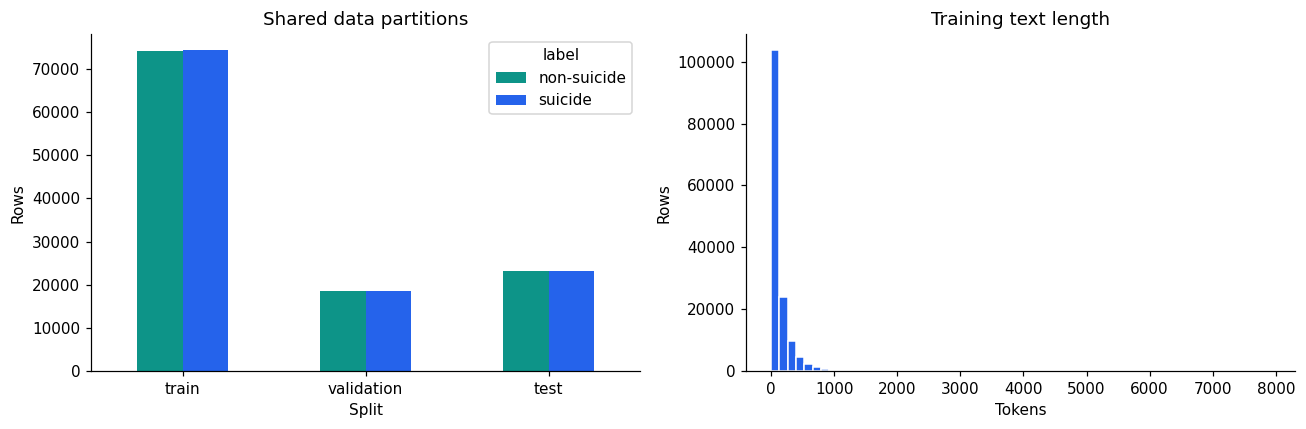

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
split_table[['non-suicide', 'suicide']].plot.bar(
    ax=axes[0], color=['#0d9488', '#2563eb'], rot=0)
axes[0].set(title='Shared data partitions', ylabel='Rows', xlabel='Split')
axes[1].hist(train_df['cleaned_text'].str.split().str.len(), bins=60,
             color='#2563eb', edgecolor='white')
axes[1].set(title='Training text length', xlabel='Tokens', ylabel='Rows')
show_figure(fig, 'data_partitions.png')


## ۴. Word2Vec محلی و تبدیل دقیق متن به بردار

توکن‌سازی یک قاعدهٔ ثابت است و یادگیری ندارد؛ یک بار برای هر متن محاسبه می‌شود.
اما `Word2Vec.fit` هر کلاینت **فقط توکن‌های آموزش همان کلاینت** را دریافت می‌کند.
بردار متن میانگین بردار تمام رخدادهای واژه‌های شناخته‌شدهٔ همان کلاینت است؛
متن بدون واژهٔ شناخته‌شده بردار صفر می‌گیرد و نرخ آن گزارش می‌شود.

برای سریع‌تر شدن پیش‌بینی ۱۸۰ مدل، رخداد توکن‌های هر دستهٔ درخواست در یک ماتریس
شمارش تنک ذخیره می‌شود. این فقط cache ورودی درخواست است؛ IDF، وزن، انتخاب واژگان
یا embedding یاد نمی‌گیرد و هیچ‌وقت وارد آموزش Word2Vec نمی‌شود.
هر کلاینت فقط ستون‌های منطبق با **واژگان محلی خودش** را می‌خواند. حاصل دقیقاً
همان میانگین‌گیری سادهٔ نسخهٔ اصلی است، با حفظ دفعات تکرار هر واژه:

$$z_k(x)=\frac{\sum_{w\in V_k}c(w,x)e_k(w)}{\sum_{w\in V_k}c(w,x)}.$$

واژگان Word2Vec با واژه‌های آموزش محلی تطبیق داده می‌شود. هیچ نرمال‌ساز،
بردارساز یا تنظیم پارامتری به دادهٔ validation/test برازش نمی‌شود.

In [7]:
def stable_hash(value):
    return int.from_bytes(md5(str(value).encode('utf-8')).digest()[:4], 'little')

class SparseTokenBatch:
    """Input-only count cache. No fitted representation, pruning, or IDF."""
    def __init__(self, documents, row_ids=None):
        self.token_to_column = {}
        indptr, indices, counts = [0], [], []
        for document in documents:
            for token, count in Counter(document).items():
                column = self.token_to_column.setdefault(token, len(self.token_to_column))
                indices.append(column)
                counts.append(count)
            indptr.append(len(indices))
        self.counts = csr_matrix(
            (np.asarray(counts, dtype=np.float32), np.asarray(indices, dtype=np.int32),
             np.asarray(indptr, dtype=np.int64)),
            shape=(len(indptr) - 1, len(self.token_to_column)), dtype=np.float32)
        self.n_rows = self.counts.shape[0]
        self.total_tokens = float(self.counts.sum())
        if row_ids is None:
            row_ids = np.arange(self.n_rows)
        self.row_ids = np.asarray(row_ids, dtype=np.int64)
        if len(self.row_ids) != self.n_rows or len(np.unique(self.row_ids)) != self.n_rows:
            raise ValueError('Query row IDs must be unique and match the number of documents.')
        self.id_digest = sha256(self.row_ids.astype('<i8').tobytes()).hexdigest()

def local_embedding(batch, keyed_vectors):
    # Match query tokens to local training vocabulary; query-only tokens are ignored.
    query_columns, local_indices = [], []
    for token, local_index in keyed_vectors.key_to_index.items():
        column = batch.token_to_column.get(token)
        if column is not None:
            query_columns.append(column)
            local_indices.append(local_index)
    features = np.zeros((batch.n_rows, keyed_vectors.vector_size), dtype=np.float32)
    known_counts = np.zeros(batch.n_rows, dtype=np.float32)
    if query_columns:
        selected = batch.counts[:, query_columns]
        known_counts = np.asarray(selected.sum(axis=1)).ravel()
        features = np.asarray(selected @ keyed_vectors.vectors[local_indices], dtype=np.float32)
        np.divide(features, known_counts[:, None], out=features,
                  where=known_counts[:, None] > 0)
    if not np.isfinite(features).all():
        raise ValueError('Non-finite embedding values.')
    coverage = {
        'token_coverage': float(known_counts.sum() / batch.total_tokens)
                          if batch.total_tokens else 0.0,
        'all_oov_fraction': float(np.mean(known_counts == 0)),
    }
    return np.ascontiguousarray(features), coverage

class LocalTextXGB:
    """All learned state belongs to one client; fit accepts local rows only."""
    def __init__(self, seed):
        self.seed = int(seed)

    def fit(self, local_documents, local_labels):
        if set(np.unique(local_labels)) != {0, 1}:
            raise ValueError('Each client must have both classes.')
        started = time.perf_counter()
        self.w2v = Word2Vec(**W2V_CONFIG, seed=self.seed, hashfxn=stable_hash)
        self.w2v.build_vocab(local_documents)
        if not self.w2v.wv.key_to_index:
            raise ValueError('Empty local Word2Vec vocabulary; increase local data or reduce min_count.')
        self.w2v.train(local_documents, total_examples=len(local_documents),
                       epochs=W2V_CONFIG['epochs'])
        w2v_seconds = time.perf_counter() - started
        local_tokens = {token for document in local_documents for token in document}
        assert set(self.w2v.wv.key_to_index) <= local_tokens, 'Non-local word in fitted vocabulary.'
        local_batch = SparseTokenBatch(local_documents)
        started = time.perf_counter()
        features, train_coverage = local_embedding(local_batch, self.w2v.wv)
        embedding_seconds = time.perf_counter() - started
        self.xgb = XGBClassifier(**XGB_CONFIG, random_state=self.seed,
                                 n_jobs=XGB_THREADS_PER_CLIENT)
        started = time.perf_counter()
        self.xgb.fit(features, np.asarray(local_labels, dtype=np.int64))
        xgb_seconds = time.perf_counter() - started
        assert np.array_equal(self.xgb.classes_, np.array([0, 1]))
        p_train = self.xgb.predict_proba(features)[:, 1]
        return {
            'w2v_seconds': w2v_seconds, 'embedding_seconds': embedding_seconds,
            'xgb_seconds': xgb_seconds,
            'fit_seconds': w2v_seconds + embedding_seconds + xgb_seconds,
            'train_accuracy_at_05': float(accuracy_score(local_labels, p_train >= 0.5)),
            'vocabulary_size': len(self.w2v.wv),
            'train_token_coverage': train_coverage['token_coverage'],
        }

    def predict_batch(self, batch):
        started = time.perf_counter()
        features, coverage = local_embedding(batch, self.w2v.wv)
        locations = np.flatnonzero(self.xgb.classes_ == 1)
        if len(locations) != 1:
            raise ValueError('Class 1 missing from the local model.')
        probabilities = self.xgb.predict_proba(features)[:, int(locations[0])].astype(np.float32)
        if not np.isfinite(probabilities).all() or np.any((probabilities < 0) | (probabilities > 1)):
            raise ValueError('Invalid local probabilities.')
        return probabilities, coverage, time.perf_counter() - started

preparation_started = time.perf_counter()
train_documents = train_df['cleaned_text'].str.split().tolist()
validation_documents = validation_df['cleaned_text'].str.split().tolist()
test_documents = test_df['cleaned_text'].str.split().tolist()
validation_batch = SparseTokenBatch(validation_documents, validation_df['row_id'])
test_batch = SparseTokenBatch(test_documents, test_df['row_id'])
query_preparation_seconds = time.perf_counter() - preparation_started
del validation_documents, test_documents
print(f'Fixed tokenization/query-cache preparation: {query_preparation_seconds:.2f} s')
print('No Word2Vec has been trained yet.')


Fixed tokenization/query-cache preparation: 4.81 s
No Word2Vec has been trained yet.


## ۵. تقسیم آموزش بین کلاینت‌ها

ردیف‌های هر کلاس با بذر مشخص درهم‌ریخته و به قطعه‌های تقریباً برابر تقسیم می‌شوند.
تخصیص هر سناریو مستقل است، اما کل دادهٔ آموزش، validation و test در همه یکسان‌اند.
این ارزیابی IID است و دربارهٔ عملکرد روی تقسیم غیر IID نتیجه‌ای نمی‌دهد.

In [8]:
def stratified_client_indices(labels, n_clients, seed):
    labels = np.asarray(labels)
    if n_clients < 1 or set(np.unique(labels)) != {0, 1}:
        raise ValueError('Expected positive client count and binary labels 0/1.')
    if min(np.bincount(labels)) < n_clients:
        raise ValueError(f'Need at least {n_clients} training rows per class.')
    rng = np.random.default_rng(seed)
    buckets = [[] for _ in range(n_clients)]
    for label in (0, 1):
        indices = np.flatnonzero(labels == label)
        rng.shuffle(indices)
        for client_id, portion in enumerate(np.array_split(indices, n_clients)):
            buckets[client_id].extend(portion.tolist())
    result = []
    for bucket in buckets:
        positions = np.asarray(bucket, dtype=np.int64)
        rng.shuffle(positions)
        assert set(labels[positions]) == {0, 1}
        result.append(positions)
    joined = np.concatenate(result)
    assert len(joined) == len(labels)
    assert np.array_equal(np.sort(joined), np.arange(len(labels))), 'Missing/overlapping client rows.'
    return result

client_plans = {}
partition_rows = []
for n_clients in CLIENT_COUNTS:
    for run_seed in REPEAT_SEEDS:
        plan = stratified_client_indices(y_train, n_clients, run_seed)
        client_plans[(n_clients, run_seed)] = plan
        for client_id, positions in enumerate(plan):
            partition_rows.append({
                'n_clients': n_clients, 'seed': run_seed, 'client_id': client_id + 1,
                'n_train': len(positions), 'n_negative': int((y_train[positions] == 0).sum()),
                'n_positive': int(y_train[positions].sum()),
                'positive_fraction': float(y_train[positions].mean()),
                'weight': len(positions) / len(y_train),
            })
client_partition_table = pd.DataFrame(partition_rows)
partition_summary = client_partition_table.groupby('n_clients').agg(
    clients_per_run=('client_id', 'max'), min_rows=('n_train', 'min'),
    mean_rows=('n_train', 'mean'), max_rows=('n_train', 'max'),
    min_positive_fraction=('positive_fraction', 'min'),
    max_positive_fraction=('positive_fraction', 'max'))
display(partition_summary)
print('Every scenario/run assigns all training rows exactly once. Held-out sets are shared.')


,clients_per_run,min_rows,mean_rows,max_rows,min_positive_fraction,max_positive_fraction
n_clients,,,,,,
10,10,14837,14838.0,14839,0.500371,0.500404
20,20,7418,7419.0,7420,0.500337,0.500404
50,50,2966,2967.6,2968,0.500337,0.500506
100,100,1483,1483.8,1485,0.500337,0.500674


Every scenario/run assigns all training rows exactly once. Held-out sets are shared.


## ۶. معیارها، اجماع سرور و اجرای یک سناریو

**اجماع نرم وزن‌دار:** وزن فقط از اندازهٔ آموزش محلی به دست می‌آید؛
از عملکرد روی تست برای تعیین وزن استفاده نمی‌شود.
کلاینت‌ها فقط ورودی validation/test را برای پیش‌بینی می‌گیرند و برچسب آن‌ها را نمی‌بینند.
محاسبهٔ احتمال تست می‌تواند هم‌زمان با inference اعتبارسنجی انجام شود، ولی هیچ‌کدام
برای بازآموزی استفاده نمی‌شود؛ سرور ابتدا آستانه را از validation تعیین و سپس تست را امتیازدهی می‌کند.

دو قرارداد تصمیم گزارش می‌شوند: آستانهٔ ثابت **۰٫۵** و آستانهٔ منتخب validation.
در تساوی F1، precision بالاتر، سپس نزدیکی به ۰٫۵ و سپس آستانهٔ کوچک‌تر ترجیح دارد.
ROC-AUC و AP از احتمال پیوستهٔ **همان اجماع** محاسبه می‌شوند و به آستانه وابسته نیستند.
AP همان Average Precision است؛ آن را با مساحت ذوزنقه‌ای زیر منحنی PR یکسان فرض نکنید.

زمان دیواری شبیه‌سازی شامل آموزش، inference و تجمیع است؛ زمان آماده‌سازی مشترک و رسم
نمودار جداست. مجموع زمان fit کلاینت‌ها نیز ثبت می‌شود؛ با اجرای موازی ممکن است از زمان
دیواری بزرگ‌تر باشد. ترافیک گزارش‌شده فقط اندازهٔ نظری probabilityهای float32 است؛
ارسال متن درخواست، سربار شبکه و رمزنگاری در آن لحاظ نشده‌اند.

In [9]:
def aggregate_probabilities(client_probabilities, client_sizes):
    values = np.asarray(client_probabilities)
    sizes = np.asarray(client_sizes, dtype=np.float64)
    if values.ndim != 2 or values.shape[0] != len(sizes) or values.shape[1] == 0:
        raise ValueError('Expected probabilities with shape (clients, query_rows).')
    if not np.isfinite(values).all() or np.any((values < 0) | (values > 1)):
        raise ValueError('Client probability outside [0, 1].')
    if not np.isfinite(sizes).all() or np.any(sizes <= 0):
        raise ValueError('Client sizes must be finite and positive.')
    weights = sizes / sizes.sum()
    result = np.asarray(weights @ values.astype(np.float64), dtype=np.float64)
    assert np.isfinite(result).all() and np.all((result >= 0) & (result <= 1))
    return result

def metric_summary(y_true, probabilities, threshold):
    predictions = (np.asarray(probabilities) >= threshold).astype(np.int64)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()
    return {
        'accuracy': accuracy_score(y_true, predictions),
        'balanced_accuracy': balanced_accuracy_score(y_true, predictions),
        'precision_positive': precision_score(y_true, predictions, zero_division=0),
        'recall_positive': recall_score(y_true, predictions, zero_division=0),
        'f1_positive': f1_score(y_true, predictions, zero_division=0),
        'f1_macro': f1_score(y_true, predictions, average='macro', zero_division=0),
        'f1_weighted': f1_score(y_true, predictions, average='weighted', zero_division=0),
        'roc_auc': roc_auc_score(y_true, probabilities),
        'average_precision': average_precision_score(y_true, probabilities),
        'specificity': tn / (tn + fp) if tn + fp else 0.0,
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
    }

def select_threshold(y_true, probabilities):
    rows = []
    for threshold in THRESHOLDS:
        predictions = np.asarray(probabilities) >= threshold
        rows.append({
            'threshold': float(threshold),
            'accuracy': accuracy_score(y_true, predictions),
            'precision_positive': precision_score(y_true, predictions, zero_division=0),
            'recall_positive': recall_score(y_true, predictions, zero_division=0),
            'f1_positive': f1_score(y_true, predictions, zero_division=0),
        })
    curve = pd.DataFrame(rows)
    ranked = curve.assign(distance_to_half=(curve['threshold'] - 0.5).abs()).sort_values(
        ['f1_positive', 'precision_positive', 'distance_to_half', 'threshold'],
        ascending=[False, False, True, True], kind='mergesort')
    return float(ranked.iloc[0]['threshold']), curve

def train_client(client_id, positions, run_seed, validation_queries, test_queries):
    # No held-out labels, other-client training rows, or global embedding enters this function.
    documents = [train_documents[int(index)] for index in positions]
    labels = y_train[positions]
    client = LocalTextXGB(seed=run_seed + 1009 * (client_id + 1))
    fit_info = client.fit(documents, labels)
    validation_p, validation_coverage, validation_seconds = client.predict_batch(validation_queries)
    test_p, test_coverage, test_seconds = client.predict_batch(test_queries)
    info = {
        'client_id': client_id + 1, 'n_train': len(positions),
        'n_positive': int(labels.sum()), 'positive_fraction': float(labels.mean()),
        **fit_info,
        'validation_token_coverage': validation_coverage['token_coverage'],
        'test_token_coverage': test_coverage['token_coverage'],
        'test_all_oov_fraction': test_coverage['all_oov_fraction'],
        'validation_predict_seconds': validation_seconds,
        'test_predict_seconds': test_seconds,
    }
    return {
        'client_id': client_id, 'info': info,
        'validation_p': validation_p, 'test_p': test_p,
        'validation_ids_digest': validation_queries.id_digest,
        'test_ids_digest': test_queries.id_digest,
        'client': client if RETAIN_CLIENT_MODELS else None,
    }

def run_federated(n_clients, run_seed):
    started = time.perf_counter()
    plan = client_plans[(n_clients, run_seed)]
    packets = [None] * n_clients
    print(f'\nK={n_clients}, seed={run_seed}: fitting {n_clients} independent local clients', flush=True)
    if MAX_PARALLEL_CLIENTS == 1:
        for client_id, positions in enumerate(plan):
            packets[client_id] = train_client(client_id, positions, run_seed,
                                                validation_batch, test_batch)
            if (client_id + 1) % max(1, n_clients // 10) == 0:
                print(f'  completed {client_id + 1}/{n_clients} clients', flush=True)
    else:
        with ThreadPoolExecutor(max_workers=min(MAX_PARALLEL_CLIENTS, n_clients)) as executor:
            futures = [executor.submit(train_client, client_id, positions, run_seed,
                                        validation_batch, test_batch)
                       for client_id, positions in enumerate(plan)]
            for completed, future in enumerate(as_completed(futures), 1):
                packet = future.result()
                packets[packet['client_id']] = packet
                if completed % max(1, n_clients // 10) == 0:
                    print(f'  completed {completed}/{n_clients} clients', flush=True)
    # All clients must answer the identical requests in the identical order.
    for packet in packets:
        assert packet['validation_ids_digest'] == validation_batch.id_digest
        assert packet['test_ids_digest'] == test_batch.id_digest
    local_summary = pd.DataFrame([packet['info'] for packet in packets])
    sizes = local_summary['n_train'].to_numpy(dtype=np.int64)
    local_summary['weight'] = sizes / sizes.sum()
    assert sizes.sum() == len(y_train)
    aggregation_started = time.perf_counter()
    validation_matrix = np.vstack([packet['validation_p'] for packet in packets])
    test_matrix = np.vstack([packet['test_p'] for packet in packets])
    validation_p = aggregate_probabilities(validation_matrix, sizes)
    test_p = aggregate_probabilities(test_matrix, sizes)
    aggregation_seconds = time.perf_counter() - aggregation_started
    pipeline_wall_seconds = time.perf_counter() - started
    # Only the server owns validation/test labels. Threshold is frozen before test scoring.
    threshold, threshold_curve = select_threshold(y_validation, validation_p)
    metric_rows = []
    for split, labels, probabilities in [
        ('validation', y_validation, validation_p), ('test', y_test, test_p)]:
        for setting, cutoff in [('default_0.50', 0.5), ('validation_selected', threshold)]:
            metric_rows.append({
                'split': split, 'setting': setting, 'threshold': cutoff,
                **metric_summary(labels, probabilities, cutoff),
            })
    metrics = pd.DataFrame(metric_rows).set_index(['split', 'setting'])
    local_summary['validation_f1_at_05'] = [
        f1_score(y_validation, row >= 0.5, zero_division=0) for row in validation_matrix]
    report = {
        'n_clients': n_clients, 'seed': run_seed, 'threshold': threshold,
        'threshold_curve': threshold_curve, 'metrics': metrics,
        'validation_probabilities': validation_p, 'test_probabilities': test_p,
        'local_summary': local_summary, 'client_sizes': sizes,
        'pipeline_wall_seconds': pipeline_wall_seconds,
        'fit_seconds_sum': float(local_summary['fit_seconds'].sum()),
        'aggregation_seconds': aggregation_seconds,
        'probability_payload_mib': (validation_matrix.nbytes + test_matrix.nbytes) / 2**20,
        'retained_clients': [packet['client'] for packet in packets] if RETAIN_CLIENT_MODELS else None,
        'test_ids_digest': test_batch.id_digest,
    }
    del packets, validation_matrix, test_matrix
    gc.collect()
    return report

scenario_reports = {}  # Re-running a scenario replaces only its own entry.

def run_scenario(n_clients):
    if n_clients not in CLIENT_COUNTS:
        raise ValueError(f'Choose a value from CLIENT_COUNTS={CLIENT_COUNTS}.')
    runs = [run_federated(n_clients, run_seed) for run_seed in REPEAT_SEEDS]
    scenario_reports[n_clients] = runs
    return runs


In [10]:
def report_scenario(runs):
    run = runs[0]
    n_clients, run_seed = run['n_clients'], run['seed']
    title = f'{n_clients} clients | seed={run_seed}'
    display(Markdown(f'### گزارش مستقل {n_clients} کلاینت'))
    if len(runs) > 1:
        display(Markdown('جدول و نمودارهای تفصیلی زیر مربوط به اولین بذر هستند؛ '
                         'جدول نهایی میانگین و انحراف معیار همهٔ تکرارها را دارد.'))
    display(run['metrics'].round(4))
    test_selected = run['metrics'].loc[('test', 'validation_selected')]
    test_predictions = (run['test_probabilities'] >= run['threshold']).astype(np.int64)
    print('\nTEST classification report — validation-selected threshold')
    print(classification_report(y_test, test_predictions, labels=[0, 1],
          target_names=CLASS_NAMES, digits=4, zero_division=0))
    print('\nTEST classification report — default threshold 0.50')
    print(classification_report(y_test, run['test_probabilities'] >= 0.5,
          labels=[0, 1], target_names=CLASS_NAMES, digits=4, zero_division=0))
    local = run['local_summary']
    print('Client diagnostics (first five):')
    display(local.head().round(4))
    print('Client diagnostic ranges:')
    display(local[['n_train', 'vocabulary_size', 'train_accuracy_at_05',
                   'validation_f1_at_05', 'test_token_coverage',
                   'test_all_oov_fraction', 'fit_seconds']].agg(['min', 'mean', 'max']).round(4))
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    ConfusionMatrixDisplay.from_predictions(
        y_test, test_predictions, labels=[0, 1], display_labels=CLASS_NAMES,
        ax=axes[0, 0], cmap='Blues', colorbar=False, values_format='d')
    axes[0, 0].set_title(f'Test confusion | threshold={run["threshold"]:.2f}')
    fpr, tpr, _ = roc_curve(y_test, run['test_probabilities'])
    axes[0, 1].plot(fpr, tpr, color=COLORS[n_clients],
                    label=f'AUC={test_selected["roc_auc"]:.4f}')
    axes[0, 1].plot([0, 1], [0, 1], '--', color='gray')
    axes[0, 1].set(title='Test ROC', xlabel='False positive rate', ylabel='True positive rate')
    axes[0, 1].legend()
    precision, recall, _ = precision_recall_curve(y_test, run['test_probabilities'])
    axes[1, 0].plot(recall, precision, color=COLORS[n_clients],
                    label=f'AP={test_selected["average_precision"]:.4f}')
    axes[1, 0].axhline(y_test.mean(), linestyle='--', color='gray', label='Positive prevalence')
    axes[1, 0].set(title='Test precision-recall', xlabel='Recall', ylabel='Precision')
    axes[1, 0].legend()
    curve = run['threshold_curve']
    for name in ['accuracy', 'precision_positive', 'recall_positive', 'f1_positive']:
        axes[1, 1].plot(curve['threshold'], curve[name], label=name)
    axes[1, 1].axvline(run['threshold'], color='black', linestyle='--')
    axes[1, 1].set(title='Threshold selection: VALIDATION only',
                   xlabel='Threshold', ylabel='Metric', ylim=(0, 1.02))
    axes[1, 1].legend(fontsize=8)
    fig.suptitle(title, fontsize=15)
    show_figure(fig, f'clients_{n_clients}_seed_{run_seed}.png')
    display(Markdown(
        f'در سناریوی **{n_clients} کلاینت**، هر کلاینت به‌طور میانگین '
        f'**{local["n_train"].mean():,.1f}** نمونهٔ آموزش دارد. '
        f'آستانهٔ منتخب اعتبارسنجی **{run["threshold"]:.2f}** است. '
        f'روی تست، Accuracy برابر **{test_selected["accuracy"]:.2%}**، '
        f'Precision کلاس مثبت **{test_selected["precision_positive"]:.2%}**، '
        f'Recall آن **{test_selected["recall_positive"]:.2%}** و '
        f'F1 آن **{test_selected["f1_positive"]:.4f}** است. '
        f'تعداد مثبت‌های ازدست‌رفته (FN) **{int(test_selected["fn"]):,}** و '
        f'هشدارهای مثبت اشتباه (FP) **{int(test_selected["fp"]):,}** است. '
        f'ROC-AUC برابر **{test_selected["roc_auc"]:.4f}** است. '
        f'زمان دیواری آموزش و پیش‌بینی این شبیه‌سازی **{run["pipeline_wall_seconds"]:.1f} ثانیه** بود؛ '
        f'مجموع زمان fit کلاینت‌ها **{run["fit_seconds_sum"]:.1f} ثانیه** بود.'
    ))


## 7. سناریوی مستقل 10 کلاینت

این سلول فقط کلاینت‌های همین سناریو را آموزش می‌دهد و جدول معیارها، گزارش
هر دو کلاس، ماتریس اغتشاش، ROC، PR و منحنی انتخاب آستانهٔ آن را نمایش می‌دهد.
پس از اجرای سلول‌های مشترک، می‌توان این سلول را به‌تنهایی اجرا کرد.
خروجی در `fl10_reports` و `scenario_reports[10]` نگهداری می‌شود.


K=10, seed=42: fitting 10 independent local clients
  completed 1/10 clients
  completed 2/10 clients
  completed 3/10 clients
  completed 4/10 clients
  completed 5/10 clients
  completed 6/10 clients
  completed 7/10 clients
  completed 8/10 clients
  completed 9/10 clients
  completed 10/10 clients


### گزارش مستقل 10 کلاینت

threshold  accuracy  ...    fn     tp
split      setting                                   ...             
validation default_0.50              0.50    0.9191  ...  1409  17152
           validation_selected       0.49    0.9191  ...  1371  17190
test       default_0.50              0.50    0.9163  ...  1859  21338
           validation_selected       0.49    0.9158  ...  1805  21392

[4 rows x 15 columns]


TEST classification report — validation-selected threshold
                 precision    recall  f1-score   support

non-suicide (0)     0.9210    0.9094    0.9152     23145
    suicide (1)     0.9107    0.9222    0.9164     23197

       accuracy                         0.9158     46342
      macro avg     0.9159    0.9158    0.9158     46342
   weighted avg     0.9159    0.9158    0.9158     46342


TEST classification report — default threshold 0.50
                 precision    recall  f1-score   support

non-suicide (0)     0.9191    0.9127    0.9159     23145
    suicide (1)     0.9135    0.9199    0.9167     23197

       accuracy                         0.9163     46342
      macro avg     0.9163    0.9163    0.9163     46342
   weighted avg     0.9163    0.9163    0.9163     46342

Client diagnostics (first five):


,client_id,n_train,n_positive,positive_fraction,w2v_seconds,embedding_seconds,xgb_seconds,fit_seconds,train_accuracy_at_05,vocabulary_size,train_token_coverage,validation_token_coverage,test_token_coverage,test_all_oov_fraction,validation_predict_seconds,test_predict_seconds,weight,validation_f1_at_05
0,1,14839,7425,0.5004,34.9392,0.0610,1.6831,36.6833,0.9620,17543,0.9922,0.9826,0.9858,0.0004,0.3509,0.4141,0.1,0.9093
1,2,14839,7425,0.5004,34.9637,0.0401,1.7015,36.7052,0.9637,17559,0.9922,0.9827,0.9860,0.0004,0.4109,0.4654,0.1,0.9101
2,3,14839,7425,0.5004,34.1786,0.3754,1.9860,36.5400,0.9619,17382,0.9923,0.9825,0.9856,0.0004,0.1549,0.2065,0.1,0.9108
3,4,14838,7425,0.5004,34.3703,0.1793,1.7931,36.3427,0.9658,17364,0.9921,0.9822,0.9854,0.0004,0.1180,0.1538,0.1,0.9102
4,5,14838,7425,0.5004,33.4387,0.0479,3.0756,36.5622,0.9655,17652,0.9917,0.9831,0.9862,0.0005,0.1537,0.1819,0.1,0.9085


Client diagnostic ranges:


,n_train,vocabulary_size,train_accuracy_at_05,validation_f1_at_05,test_token_coverage,test_all_oov_fraction,fit_seconds
min,14837.0,17364.0,0.9619,0.9080,0.9854,0.0004,30.1716
mean,14838.0,17618.2,0.9642,0.9098,0.9860,0.0004,35.3874
max,14839.0,18018.0,0.9670,0.9115,0.9862,0.0005,36.8590


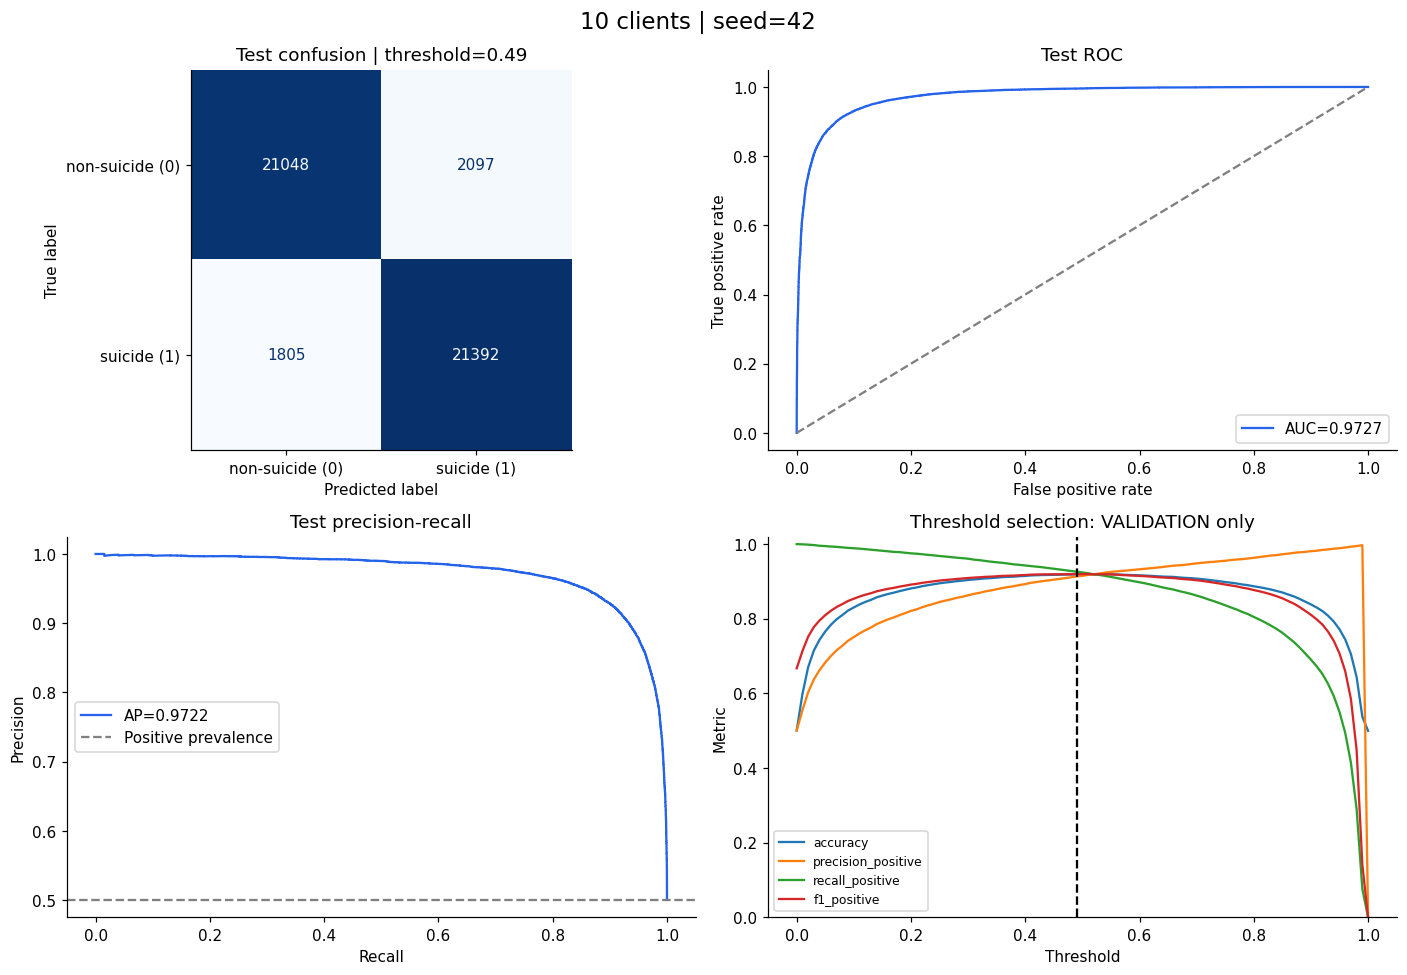

در سناریوی **10 کلاینت**، هر کلاینت به‌طور میانگین **14,838.0** نمونهٔ آموزش دارد. آستانهٔ منتخب اعتبارسنجی **0.49** است. روی تست، Accuracy برابر **91.58%**، Precision کلاس مثبت **91.07%**، Recall آن **92.22%** و F1 آن **0.9164** است. تعداد مثبت‌های ازدست‌رفته (FN) **1,805** و هشدارهای مثبت اشتباه (FP) **2,097** است. ROC-AUC برابر **0.9727** است. زمان دیواری آموزش و پیش‌بینی این شبیه‌سازی **107.6 ثانیه** بود؛ مجموع زمان fit کلاینت‌ها **353.9 ثانیه** بود.

In [11]:
fl10_reports = run_scenario(10)
report_scenario(fl10_reports)


## 8. سناریوی مستقل 20 کلاینت

این سلول فقط کلاینت‌های همین سناریو را آموزش می‌دهد و جدول معیارها، گزارش
هر دو کلاس، ماتریس اغتشاش، ROC، PR و منحنی انتخاب آستانهٔ آن را نمایش می‌دهد.
پس از اجرای سلول‌های مشترک، می‌توان این سلول را به‌تنهایی اجرا کرد.
خروجی در `fl20_reports` و `scenario_reports[20]` نگهداری می‌شود.


K=20, seed=42: fitting 20 independent local clients
  completed 2/20 clients
  completed 4/20 clients
  completed 6/20 clients
  completed 8/20 clients
  completed 10/20 clients
  completed 12/20 clients
  completed 14/20 clients
  completed 16/20 clients
  completed 18/20 clients
  completed 20/20 clients


### گزارش مستقل 20 کلاینت

threshold  accuracy  ...    fn     tp
split      setting                                   ...             
validation default_0.50              0.50    0.9120  ...  1531  17030
           validation_selected       0.52    0.9133  ...  1599  16962
test       default_0.50              0.50    0.9092  ...  1980  21217
           validation_selected       0.52    0.9093  ...  2096  21101

[4 rows x 15 columns]


TEST classification report — validation-selected threshold
                 precision    recall  f1-score   support

non-suicide (0)     0.9094    0.9089    0.9091     23145
    suicide (1)     0.9091    0.9096    0.9094     23197

       accuracy                         0.9093     46342
      macro avg     0.9093    0.9093    0.9093     46342
   weighted avg     0.9093    0.9093    0.9093     46342


TEST classification report — default threshold 0.50
                 precision    recall  f1-score   support

non-suicide (0)     0.9135    0.9038    0.9087     23145
    suicide (1)     0.9050    0.9146    0.9098     23197

       accuracy                         0.9092     46342
      macro avg     0.9093    0.9092    0.9092     46342
   weighted avg     0.9093    0.9092    0.9092     46342

Client diagnostics (first five):


,client_id,n_train,n_positive,positive_fraction,w2v_seconds,embedding_seconds,xgb_seconds,fit_seconds,train_accuracy_at_05,vocabulary_size,train_token_coverage,validation_token_coverage,test_token_coverage,test_all_oov_fraction,validation_predict_seconds,test_predict_seconds,weight,validation_f1_at_05
0,1,7420,3713,0.5004,15.6200,0.1599,1.8665,17.6464,0.9801,12450,0.9892,0.9767,0.9797,0.0005,0.1352,0.1629,0.05,0.9004
1,2,7420,3713,0.5004,15.9215,0.1293,1.5793,17.6301,0.9810,12421,0.9889,0.9766,0.9797,0.0005,0.1829,0.3587,0.05,0.9008
2,3,7420,3713,0.5004,16.2463,0.0203,1.4781,17.7447,0.9837,12502,0.9892,0.9770,0.9801,0.0005,0.1312,0.3406,0.05,0.8983
3,4,7420,3713,0.5004,15.7180,0.1361,1.5083,17.3624,0.9809,12326,0.9889,0.9763,0.9799,0.0005,0.0939,0.2427,0.05,0.8986
4,5,7420,3713,0.5004,16.0702,0.1397,1.7964,18.0063,0.9817,12195,0.9892,0.9762,0.9794,0.0005,0.1102,0.1358,0.05,0.8999


Client diagnostic ranges:


,n_train,vocabulary_size,train_accuracy_at_05,validation_f1_at_05,test_token_coverage,test_all_oov_fraction,fit_seconds
min,7418.0,12059.00,0.9779,0.8982,0.9792,0.0004,16.6868
mean,7419.0,12430.25,0.9825,0.9000,0.9798,0.0005,17.3766
max,7420.0,12684.00,0.9861,0.9023,0.9804,0.0005,18.2007


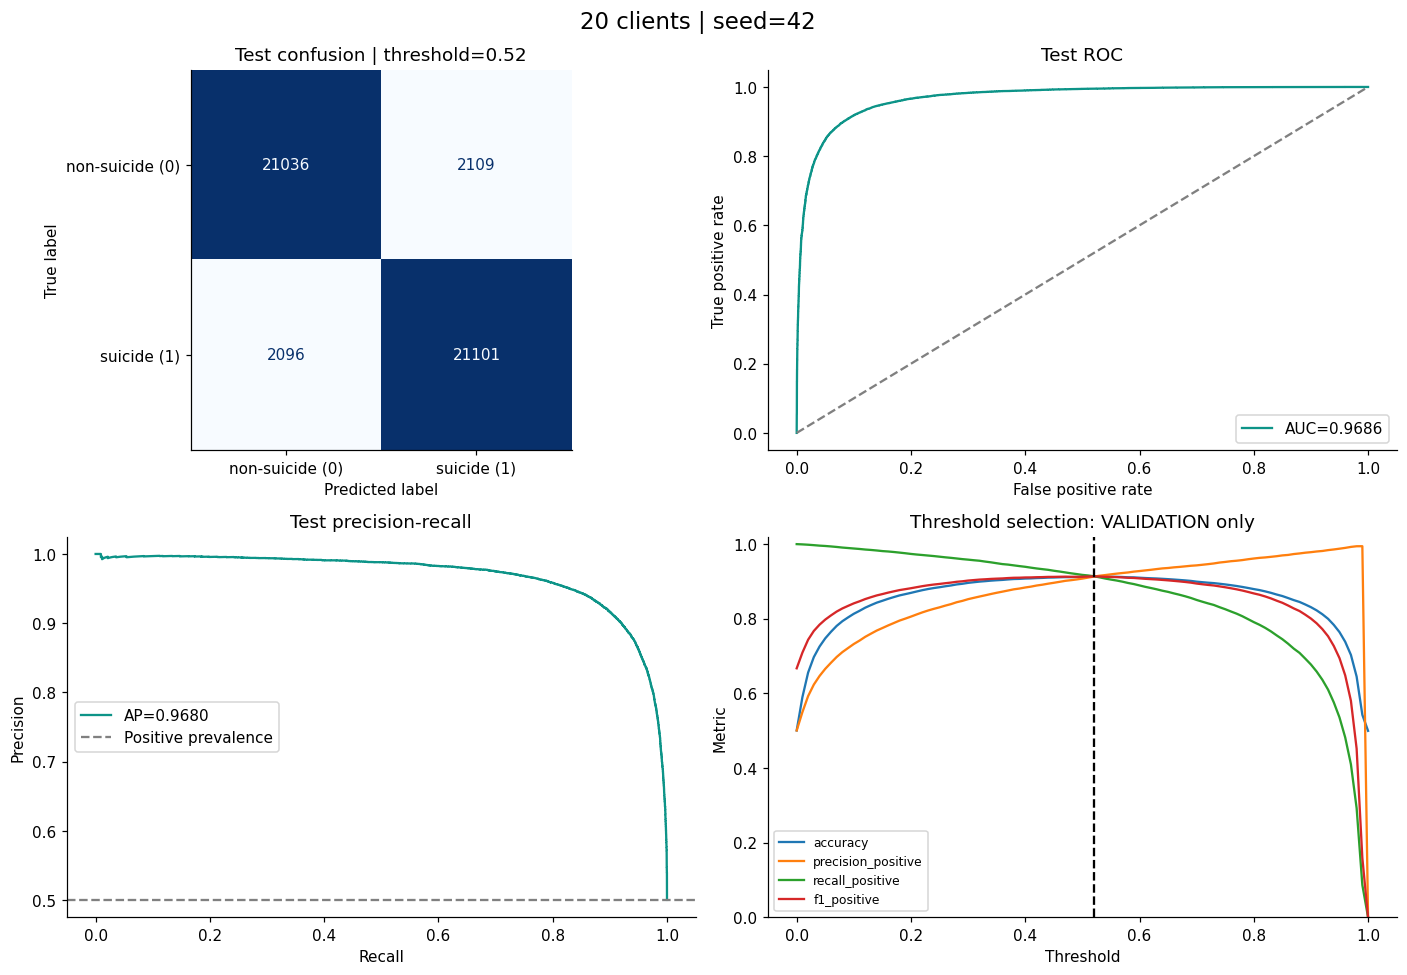

در سناریوی **20 کلاینت**، هر کلاینت به‌طور میانگین **7,419.0** نمونهٔ آموزش دارد. آستانهٔ منتخب اعتبارسنجی **0.52** است. روی تست، Accuracy برابر **90.93%**، Precision کلاس مثبت **90.91%**، Recall آن **90.96%** و F1 آن **0.9094** است. تعداد مثبت‌های ازدست‌رفته (FN) **2,096** و هشدارهای مثبت اشتباه (FP) **2,109** است. ROC-AUC برابر **0.9686** است. زمان دیواری آموزش و پیش‌بینی این شبیه‌سازی **91.1 ثانیه** بود؛ مجموع زمان fit کلاینت‌ها **347.5 ثانیه** بود.

In [12]:
fl20_reports = run_scenario(20)
report_scenario(fl20_reports)


## 9. سناریوی مستقل 50 کلاینت

این سلول فقط کلاینت‌های همین سناریو را آموزش می‌دهد و جدول معیارها، گزارش
هر دو کلاس، ماتریس اغتشاش، ROC، PR و منحنی انتخاب آستانهٔ آن را نمایش می‌دهد.
پس از اجرای سلول‌های مشترک، می‌توان این سلول را به‌تنهایی اجرا کرد.
خروجی در `fl50_reports` و `scenario_reports[50]` نگهداری می‌شود.


K=50, seed=42: fitting 50 independent local clients
  completed 5/50 clients
  completed 10/50 clients
  completed 15/50 clients
  completed 20/50 clients
  completed 25/50 clients
  completed 30/50 clients
  completed 35/50 clients
  completed 40/50 clients
  completed 45/50 clients
  completed 50/50 clients


### گزارش مستقل 50 کلاینت

threshold  accuracy  ...    fn     tp
split      setting                                   ...             
validation default_0.50              0.50    0.8927  ...  1801  16760
           validation_selected       0.54    0.8946  ...  1991  16570
test       default_0.50              0.50    0.8923  ...  2296  20901
           validation_selected       0.54    0.8930  ...  2572  20625

[4 rows x 15 columns]


TEST classification report — validation-selected threshold
                 precision    recall  f1-score   support

non-suicide (0)     0.8898    0.8969    0.8933     23145
    suicide (1)     0.8963    0.8891    0.8927     23197

       accuracy                         0.8930     46342
      macro avg     0.8930    0.8930    0.8930     46342
   weighted avg     0.8930    0.8930    0.8930     46342


TEST classification report — default threshold 0.50
                 precision    recall  f1-score   support

non-suicide (0)     0.8991    0.8835    0.8912     23145
    suicide (1)     0.8857    0.9010    0.8933     23197

       accuracy                         0.8923     46342
      macro avg     0.8924    0.8922    0.8922     46342
   weighted avg     0.8924    0.8923    0.8922     46342

Client diagnostics (first five):


,client_id,n_train,n_positive,positive_fraction,w2v_seconds,embedding_seconds,xgb_seconds,fit_seconds,train_accuracy_at_05,vocabulary_size,train_token_coverage,validation_token_coverage,test_token_coverage,test_all_oov_fraction,validation_predict_seconds,test_predict_seconds,weight,validation_f1_at_05
0,1,2968,1485,0.5003,5.9659,0.0166,1.3555,7.3381,0.9973,7367,0.9823,0.9638,0.9669,0.0007,0.0918,0.1099,0.02,0.8774
1,2,2968,1485,0.5003,6.6803,0.0101,1.1950,7.8854,0.9987,7846,0.9829,0.9649,0.9679,0.0006,0.1401,0.1731,0.02,0.8793
2,3,2968,1485,0.5003,6.5749,0.0126,1.3141,7.9017,0.9976,7748,0.9830,0.9649,0.9678,0.0006,0.2030,0.2010,0.02,0.8793
3,4,2968,1485,0.5003,6.4724,0.0566,1.1544,7.6835,0.9970,7483,0.9826,0.9644,0.9675,0.0005,0.1181,0.1257,0.02,0.8784
4,5,2968,1485,0.5003,5.7495,0.0095,1.2246,6.9836,0.9963,7820,0.9815,0.9652,0.9680,0.0006,0.0940,0.1225,0.02,0.8761


Client diagnostic ranges:


,n_train,vocabulary_size,train_accuracy_at_05,validation_f1_at_05,test_token_coverage,test_all_oov_fraction,fit_seconds
min,2966.0,7306.00,0.9933,0.8743,0.9664,0.0005,5.9643
mean,2967.6,7654.56,0.9973,0.8779,0.9677,0.0006,7.2370
max,2968.0,8228.00,0.9990,0.8829,0.9689,0.0007,7.9284


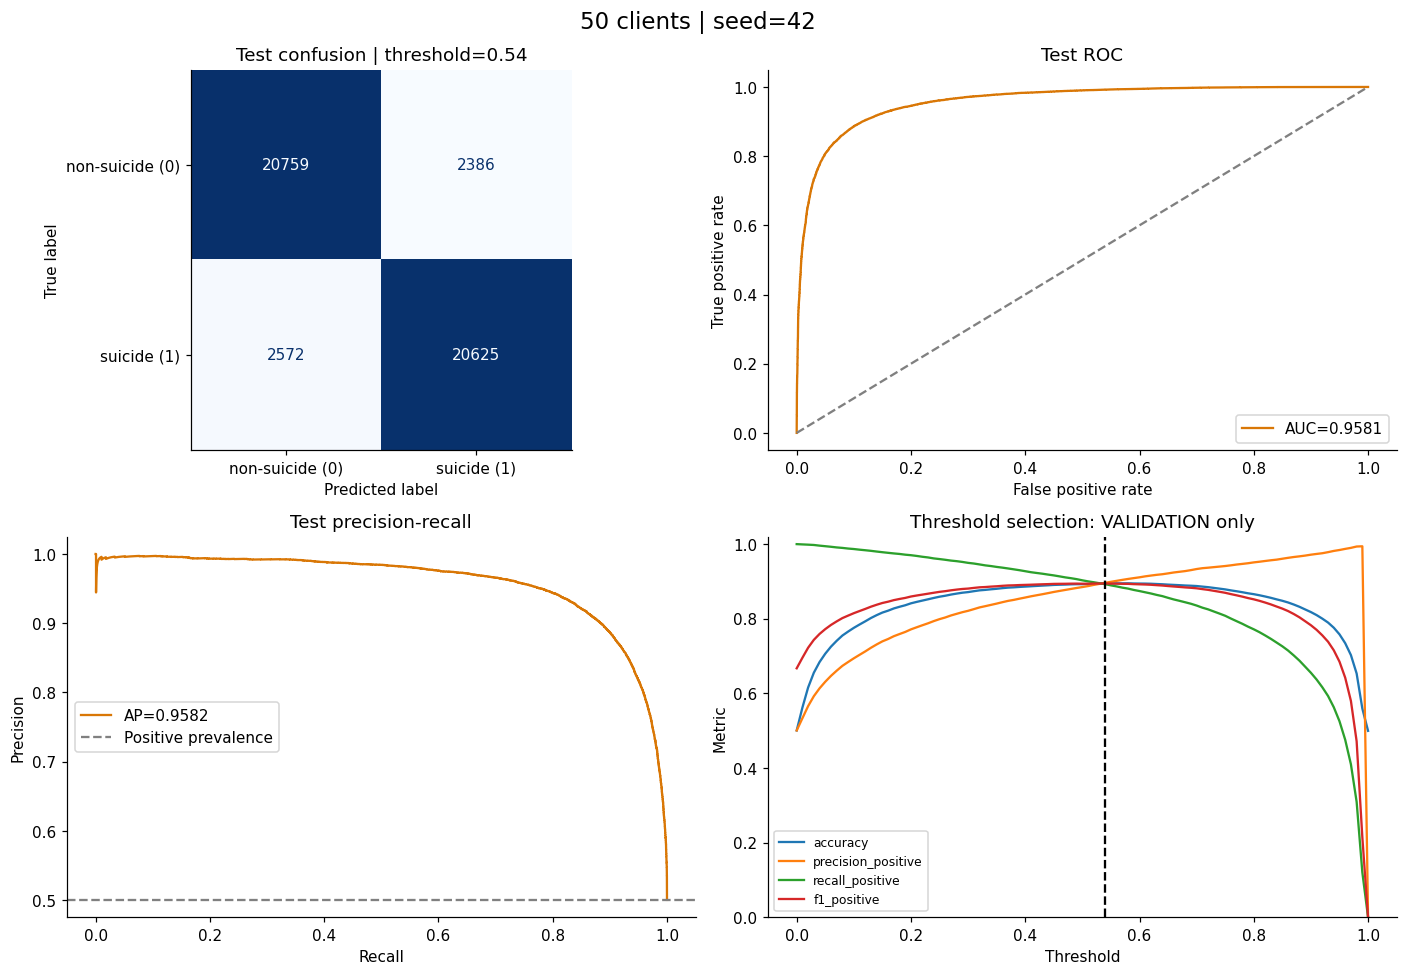

در سناریوی **50 کلاینت**، هر کلاینت به‌طور میانگین **2,967.6** نمونهٔ آموزش دارد. آستانهٔ منتخب اعتبارسنجی **0.54** است. روی تست، Accuracy برابر **89.30%**، Precision کلاس مثبت **89.63%**، Recall آن **88.91%** و F1 آن **0.8927** است. تعداد مثبت‌های ازدست‌رفته (FN) **2,572** و هشدارهای مثبت اشتباه (FP) **2,386** است. ROC-AUC برابر **0.9581** است. زمان دیواری آموزش و پیش‌بینی این شبیه‌سازی **98.5 ثانیه** بود؛ مجموع زمان fit کلاینت‌ها **361.8 ثانیه** بود.

In [13]:
fl50_reports = run_scenario(50)
report_scenario(fl50_reports)


## 10. سناریوی مستقل 100 کلاینت

این سلول فقط کلاینت‌های همین سناریو را آموزش می‌دهد و جدول معیارها، گزارش
هر دو کلاس، ماتریس اغتشاش، ROC، PR و منحنی انتخاب آستانهٔ آن را نمایش می‌دهد.
پس از اجرای سلول‌های مشترک، می‌توان این سلول را به‌تنهایی اجرا کرد.
خروجی در `fl100_reports` و `scenario_reports[100]` نگهداری می‌شود.


K=100, seed=42: fitting 100 independent local clients
  completed 10/100 clients
  completed 20/100 clients
  completed 30/100 clients
  completed 40/100 clients
  completed 50/100 clients
  completed 60/100 clients
  completed 70/100 clients
  completed 80/100 clients
  completed 90/100 clients
  completed 100/100 clients


### گزارش مستقل 100 کلاینت

threshold  accuracy  ...    fn     tp
split      setting                                   ...             
validation default_0.50               0.5    0.8712  ...  2042  16519
           validation_selected        0.5    0.8712  ...  2042  16519
test       default_0.50               0.5    0.8700  ...  2612  20585
           validation_selected        0.5    0.8700  ...  2612  20585

[4 rows x 15 columns]


TEST classification report — validation-selected threshold
                 precision    recall  f1-score   support

non-suicide (0)     0.8831    0.8526    0.8676     23145
    suicide (1)     0.8578    0.8874    0.8724     23197

       accuracy                         0.8700     46342
      macro avg     0.8705    0.8700    0.8700     46342
   weighted avg     0.8704    0.8700    0.8700     46342


TEST classification report — default threshold 0.50
                 precision    recall  f1-score   support

non-suicide (0)     0.8831    0.8526    0.8676     23145
    suicide (1)     0.8578    0.8874    0.8724     23197

       accuracy                         0.8700     46342
      macro avg     0.8705    0.8700    0.8700     46342
   weighted avg     0.8704    0.8700    0.8700     46342

Client diagnostics (first five):


,client_id,n_train,n_positive,positive_fraction,w2v_seconds,embedding_seconds,xgb_seconds,fit_seconds,train_accuracy_at_05,vocabulary_size,train_token_coverage,validation_token_coverage,test_token_coverage,test_all_oov_fraction,validation_predict_seconds,test_predict_seconds,weight,validation_f1_at_05
0,1,1485,743,0.5003,2.7302,0.0069,0.8977,3.6347,1.0000,4977,0.9741,0.9495,0.9529,0.0007,0.0952,0.1493,0.01,0.8485
1,2,1485,743,0.5003,2.9329,0.0116,0.7766,3.7210,0.9987,5072,0.9755,0.9510,0.9542,0.0008,0.1074,0.1288,0.01,0.8547
2,3,1485,743,0.5003,2.8583,0.0068,0.9031,3.7681,1.0000,5316,0.9746,0.9517,0.9546,0.0007,0.1733,0.1175,0.01,0.8508
3,4,1485,743,0.5003,3.0249,0.0073,0.9599,3.9921,1.0000,5364,0.9764,0.9525,0.9554,0.0007,0.1193,0.1302,0.01,0.8511
4,5,1485,743,0.5003,2.7403,0.0094,0.9261,3.6758,0.9993,5299,0.9754,0.9519,0.9551,0.0007,0.0862,0.1085,0.01,0.8542


Client diagnostic ranges:


,n_train,vocabulary_size,train_accuracy_at_05,validation_f1_at_05,test_token_coverage,test_all_oov_fraction,fit_seconds
min,1483.0,4631.00,0.9987,0.8439,0.9497,0.0006,3.0944
mean,1483.8,5192.13,0.9997,0.8509,0.9542,0.0007,3.7253
max,1485.0,5819.00,1.0000,0.8598,0.9572,0.0008,4.2851


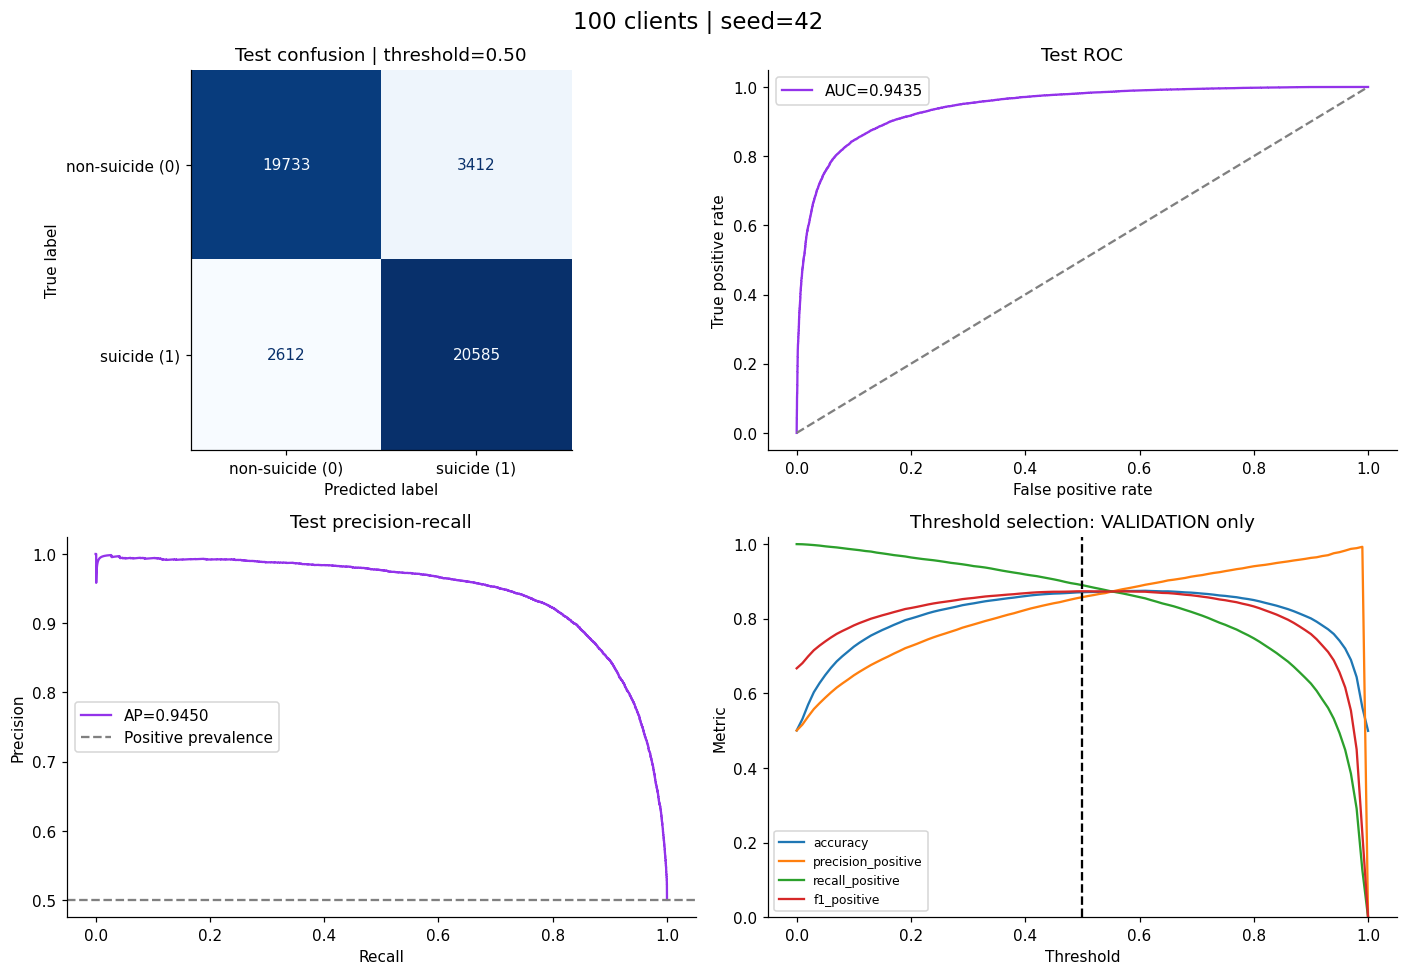

در سناریوی **100 کلاینت**، هر کلاینت به‌طور میانگین **1,483.8** نمونهٔ آموزش دارد. آستانهٔ منتخب اعتبارسنجی **0.50** است. روی تست، Accuracy برابر **87.00%**، Precision کلاس مثبت **85.78%**، Recall آن **88.74%** و F1 آن **0.8724** است. تعداد مثبت‌های ازدست‌رفته (FN) **2,612** و هشدارهای مثبت اشتباه (FP) **3,412** است. ROC-AUC برابر **0.9435** است. زمان دیواری آموزش و پیش‌بینی این شبیه‌سازی **101.9 ثانیه** بود؛ مجموع زمان fit کلاینت‌ها **372.5 ثانیه** بود.

In [14]:
fl100_reports = run_scenario(100)
report_scenario(fl100_reports)


## ۱۱. جدول مقایسهٔ نهایی

جدول اصلی از آستانهٔ منتخب validation هر اجرا استفاده می‌کند؛ جدول دوم
تست همهٔ سناریوها را با آستانهٔ یکسان ۰٫۵ نشان می‌دهد. این دو جدول اثر تغییر
کیفیت احتمال‌ها را از اثر تنظیم آستانه قابل تفکیک می‌کنند.
سناریوی پیشنهادی فقط با **F1 اعتبارسنجی** انتخاب می‌شود، نه با بیشترین امتیاز تست.
با بیش از یک بذر، انحراف معیار نمونه‌ای میان تکرارها نیز گزارش می‌شود؛
این مقدار فاصلهٔ اطمینان تعمیم به جمعیت یا عدم‌قطعیت خود تست نیست.

آستانهٔ منتخب validation ممکن است روی test از آستانهٔ ۰٫۵ ضعیف‌تر باشد؛
پس از مشاهدهٔ تست، انتخاب آستانه را تغییر ندهید.

In [15]:
comparison_rows, default_rows = [], []
for n_clients in sorted(scenario_reports):
    for report in scenario_reports[n_clients]:
        selected = report['metrics'].loc[('test', 'validation_selected')]
        validation = report['metrics'].loc[('validation', 'validation_selected')]
        default = report['metrics'].loc[('test', 'default_0.50')]
        local = report['local_summary']
        comparison_rows.append({
            'n_clients': n_clients, 'seed': report['seed'], 'threshold': report['threshold'],
            'mean_client_rows': local['n_train'].mean(),
            'validation_f1_positive': validation['f1_positive'],
            'validation_roc_auc': validation['roc_auc'],
            **{f'test_{name}': value for name, value in selected.items()},
            'mean_client_vocabulary': local['vocabulary_size'].mean(),
            'mean_test_token_coverage': local['test_token_coverage'].mean(),
            'mean_test_all_oov_fraction': local['test_all_oov_fraction'].mean(),
            'pipeline_wall_seconds': report['pipeline_wall_seconds'],
            'fit_seconds_sum': report['fit_seconds_sum'],
            'probability_payload_mib': report['probability_payload_mib'],
        })
        default_rows.append({'n_clients': n_clients, 'seed': report['seed'], 'threshold': 0.5,
                             **{f'test_{name}': value for name, value in default.items()}})
if not comparison_rows:
    raise RuntimeError('Run at least one scenario before building the comparison.')
comparison_table = pd.DataFrame(comparison_rows).sort_values(['n_clients', 'seed'])
default_comparison_table = pd.DataFrame(default_rows).sort_values(['n_clients', 'seed'])
grouped = comparison_table.drop(columns='seed').groupby('n_clients')
comparison_mean = grouped.mean()
comparison_std = grouped.std(ddof=1)
run_counts = comparison_table.groupby('n_clients').size()
main_columns = ['threshold', 'mean_client_rows', 'validation_f1_positive',
    'test_accuracy', 'test_precision_positive', 'test_recall_positive',
    'test_f1_positive', 'test_f1_macro', 'test_roc_auc', 'test_average_precision',
    'test_fn', 'test_fp', 'pipeline_wall_seconds']
print('TEST — validation-selected thresholds; proportions are on a 0–1 scale')
display(comparison_mean[main_columns].round(4))
if (run_counts > 1).any():
    print('Across-run sample standard deviation (NaN means fewer than 2 runs):')
    display(comparison_std[main_columns].round(4))
else:
    print('One run per scenario: no across-run uncertainty estimate.')
print('TEST — common fixed threshold 0.50')
display(default_comparison_table.drop(columns='seed').groupby('n_clients').mean()[
    ['test_accuracy', 'test_precision_positive', 'test_recall_positive',
     'test_f1_positive', 'test_f1_macro', 'test_roc_auc', 'test_average_precision']].round(4))
ranking = comparison_mean.reset_index().sort_values(
    ['validation_f1_positive', 'validation_roc_auc', 'n_clients'],
    ascending=[False, False, True], kind='mergesort')
recommended_clients = int(ranking.iloc[0]['n_clients'])
print('Scenario selected by VALIDATION F1:', recommended_clients, 'clients')
missing = sorted(set(CLIENT_COUNTS) - set(scenario_reports))
if missing:
    print('Not yet run:', missing)
assert all(report['test_ids_digest'] == test_batch.id_digest
           for reports in scenario_reports.values() for report in reports)


TEST — validation-selected thresholds; proportions are on a 0–1 scale


,threshold,mean_client_rows,validation_f1_positive,test_accuracy,test_precision_positive,test_recall_positive,test_f1_positive,test_f1_macro,test_roc_auc,test_average_precision,test_fn,test_fp,pipeline_wall_seconds
n_clients,,,,,,,,,,,,,
10,0.49,14838.0,0.9198,0.9158,0.9107,0.9222,0.9164,0.9158,0.9727,0.9722,1805.0,2097.0,107.6356
20,0.52,7419.0,0.9134,0.9093,0.9091,0.9096,0.9094,0.9093,0.9686,0.9680,2096.0,2109.0,91.1462
50,0.54,2967.6,0.8945,0.8930,0.8963,0.8891,0.8927,0.8930,0.9581,0.9582,2572.0,2386.0,98.4640
100,0.50,1483.8,0.8737,0.8700,0.8578,0.8874,0.8724,0.8700,0.9435,0.9450,2612.0,3412.0,101.8770


One run per scenario: no across-run uncertainty estimate.
TEST — common fixed threshold 0.50


,test_accuracy,test_precision_positive,test_recall_positive,test_f1_positive,test_f1_macro,test_roc_auc,test_average_precision
n_clients,,,,,,,
10,0.9163,0.9135,0.9199,0.9167,0.9163,0.9727,0.9722
20,0.9092,0.9050,0.9146,0.9098,0.9092,0.9686,0.9680
50,0.8923,0.8857,0.9010,0.8933,0.8922,0.9581,0.9582
100,0.8700,0.8578,0.8874,0.8724,0.8700,0.9435,0.9450


Scenario selected by VALIDATION F1: 10 clients


## ۱۲. نمودارهای مقایسه‌ای

محور افقی تعداد کلاینت است. هر نقطه میانگین تکرارهای همان سناریو است؛
میلهٔ خطا فقط در صورت حداقل دو تکرار، انحراف معیار میان بذرها را نشان می‌دهد.
نمودار ROC/PR و ماتریس‌های اغتشاش مربوط به اولین بذر مشترک‌اند؛ احتمال‌های
تکرارهای مختلف با هم ترکیب نشده‌اند تا یک ensemble اضافی ساخته نشود.

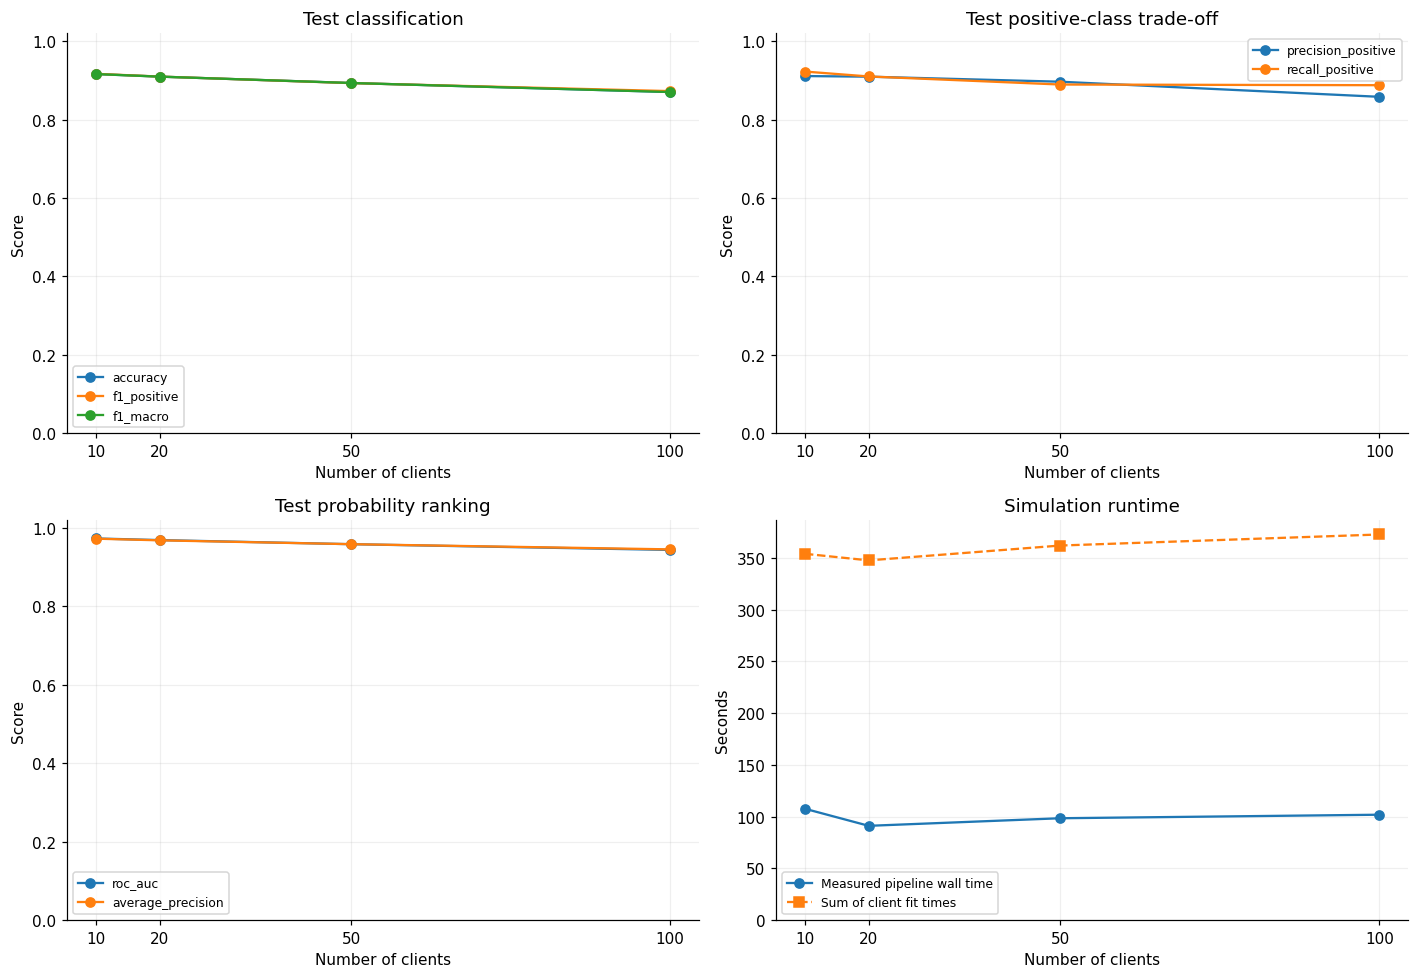

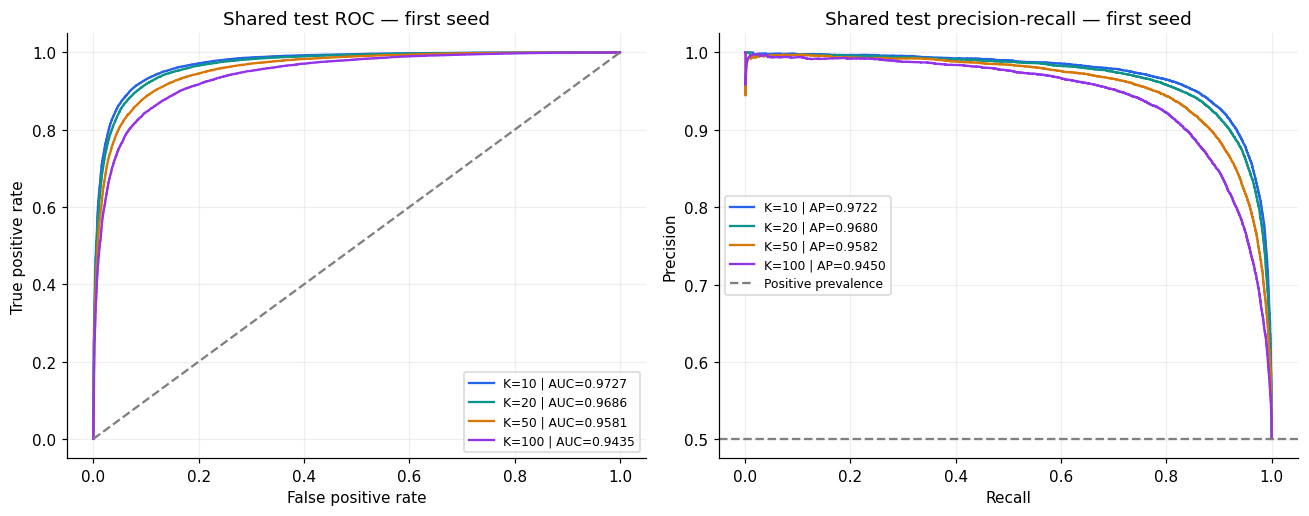

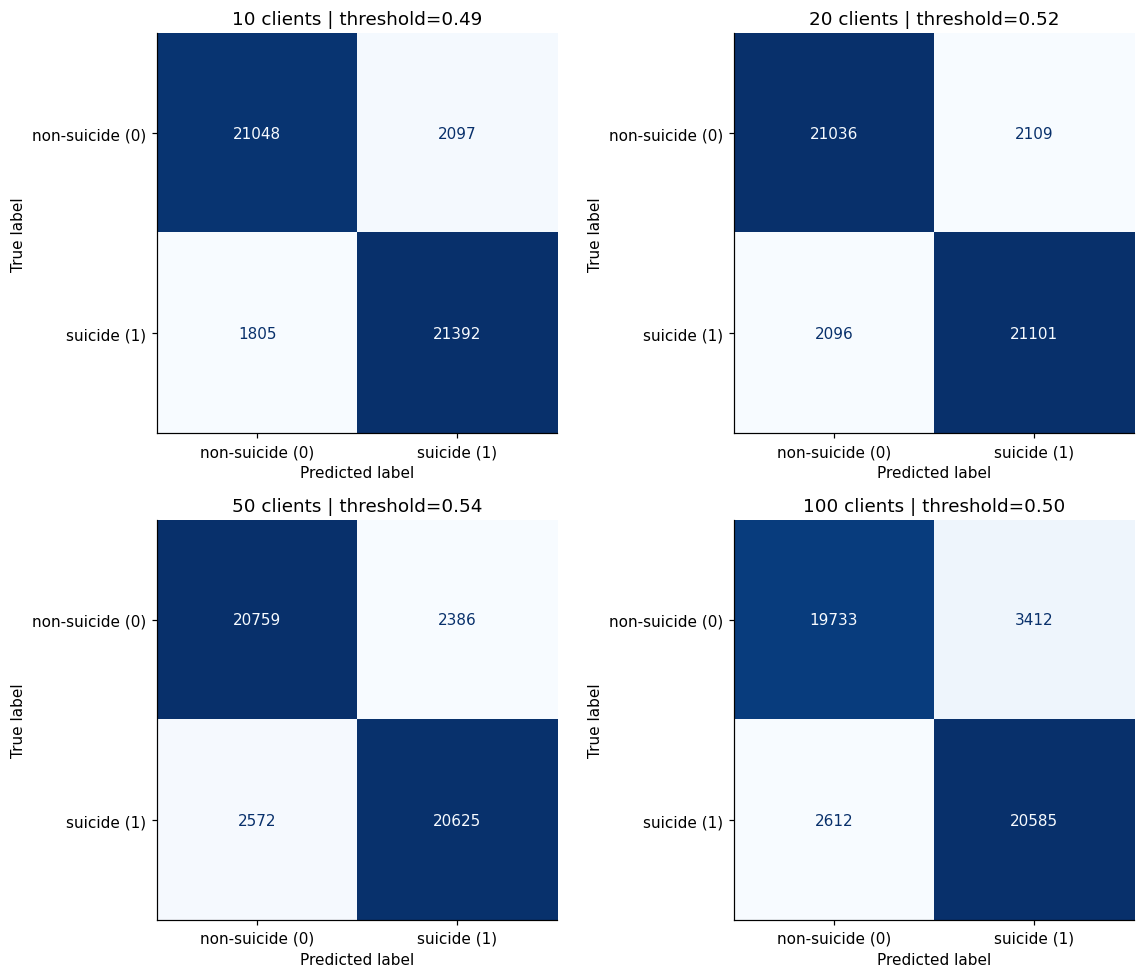

In [16]:
x = comparison_mean.index.to_numpy(dtype=int)
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
panels = [
    (axes[0, 0], ['test_accuracy', 'test_f1_positive', 'test_f1_macro'], 'Test classification'),
    (axes[0, 1], ['test_precision_positive', 'test_recall_positive'], 'Test positive-class trade-off'),
    (axes[1, 0], ['test_roc_auc', 'test_average_precision'], 'Test probability ranking'),
]
for ax, columns, title in panels:
    for column in columns:
        errors = comparison_std[column].reindex(x)
        error_values = errors.fillna(0).to_numpy() if errors.notna().any() else None
        ax.errorbar(x, comparison_mean[column], yerr=error_values,
                    marker='o', capsize=3, label=column.replace('test_', ''))
    ax.set(title=title, xlabel='Number of clients', ylabel='Score', ylim=(0, 1.02), xticks=x)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
axes[1, 1].plot(x, comparison_mean['pipeline_wall_seconds'], 'o-',
                 label='Measured pipeline wall time')
axes[1, 1].plot(x, comparison_mean['fit_seconds_sum'], 's--',
                 label='Sum of client fit times')
axes[1, 1].set(title='Simulation runtime', xlabel='Number of clients',
               ylabel='Seconds', xticks=x, ylim=(0, None))
axes[1, 1].legend(fontsize=8)
axes[1, 1].grid(alpha=0.2)
show_figure(fig, 'comparison_metrics_and_time.png')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for n_clients in sorted(scenario_reports):
    report = scenario_reports[n_clients][0]
    score = report['metrics'].loc[('test', 'validation_selected')]
    fpr, tpr, _ = roc_curve(y_test, report['test_probabilities'])
    axes[0].plot(fpr, tpr, color=COLORS[n_clients],
                 label=f'K={n_clients} | AUC={score["roc_auc"]:.4f}')
    precision, recall, _ = precision_recall_curve(y_test, report['test_probabilities'])
    axes[1].plot(recall, precision, color=COLORS[n_clients],
                 label=f'K={n_clients} | AP={score["average_precision"]:.4f}')
axes[0].plot([0, 1], [0, 1], '--', color='gray')
axes[1].axhline(y_test.mean(), linestyle='--', color='gray', label='Positive prevalence')
axes[0].set(title='Shared test ROC — first seed', xlabel='False positive rate', ylabel='True positive rate')
axes[1].set(title='Shared test precision-recall — first seed', xlabel='Recall', ylabel='Precision')
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
show_figure(fig, 'comparison_roc_pr.png')

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, n_clients in zip(axes.flat, sorted(scenario_reports)):
    report = scenario_reports[n_clients][0]
    predictions = report['test_probabilities'] >= report['threshold']
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions, labels=[0, 1], display_labels=CLASS_NAMES,
        ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(f'{n_clients} clients | threshold={report["threshold"]:.2f}')
for ax in axes.flat[len(scenario_reports):]:
    ax.axis('off')
show_figure(fig, 'comparison_confusion_matrices.png')


In [17]:
selected = comparison_mean.loc[recommended_clients]
smallest, largest = int(x.min()), int(x.max())
change_f1 = comparison_mean.loc[largest, 'test_f1_positive'] - comparison_mean.loc[smallest, 'test_f1_positive']
change_coverage = (comparison_mean.loc[largest, 'mean_test_token_coverage'] -
                   comparison_mean.loc[smallest, 'mean_test_token_coverage'])
display(Markdown(
    f'### تفسیر نتایج همین اجرا\n\n'
    f'- از میان سناریوهای اجراشده، معیار اعتبارسنجی **{recommended_clients} کلاینت** را انتخاب کرد؛ '
    f'میانگین F1 اعتبارسنجی آن **{selected["validation_f1_positive"]:.4f}** است. '
    f'در تست مشترک این سناریو، Accuracy برابر **{selected["test_accuracy"]:.2%}**، '
    f'F1 مثبت **{selected["test_f1_positive"]:.4f}**، '
    f'Recall مثبت **{selected["test_recall_positive"]:.2%}** و '
    f'ROC-AUC **{selected["test_roc_auc"]:.4f}** است.\n'
    f'- با افزایش تعداد کلاینت از **{smallest}** به **{largest}**، میانگین حجم آموزش محلی از '
    f'**{comparison_mean.loc[smallest, "mean_client_rows"]:,.1f}** به '
    f'**{comparison_mean.loc[largest, "mean_client_rows"]:,.1f}** رسید. '
    f'تغییر مشاهده‌شدهٔ F1 تست **{change_f1:+.4f}** و تغییر پوشش توکن تست '
    f'**{change_coverage * 100:+.2f} واحد درصد** است.\n'
    f'- افزایش تعداد کلاینت، دادهٔ هر مدل و کیفیت Word2Vec محلی را تغییر می‌دهد و هم‌زمان '
    f'تعداد اعضای ensemble را زیاد می‌کند. جهت اثر نهایی را باید از جدول خواند؛ '
    f'بهبود یکنواخت با افزایش کلاینت تضمین نشده است. این آزمایش اثر مشترک '
    f'تقسیم داده، بردارسازی محلی و اجماع را اندازه می‌گیرد.\n'
    f'- Precision سهم هشدارهای مثبت درست و Recall سهم نمونه‌های مثبت کشف‌شده است؛ '
    f'ستون FN تعداد مثبت‌های کشف‌نشده را نشان می‌دهد. F1 تعادل این دو معیار است. '
    f'آستانه با F1 تنظیم شده، نه برای تضمین Recall مشخص.\n'
    f'- جدول آستانهٔ ثابت ۰٫۵ را نیز بررسی کنید: اختلاف عملکرد با آستانهٔ منتخب '
    f'نشان می‌دهد چه مقدار از تغییر نتیجه به انتخاب آستانه مربوط است. '
    f'ROC-AUC و AP بدون آستانه محاسبه می‌شوند.\n'
    f'- تمام سناریوها بر یک test مشترک و یک تقسیم IID ارزیابی شده‌اند. '
    f'نتایج مشاهده‌شده به‌تنهایی برتری آماری، عملکرد غیر IID یا تضمین حریم خصوصی را اثبات نمی‌کنند. '
    f'برای برآورد پایداری، چند بذر از پیش تعیین‌شده اجرا کنید و پس از دیدن test تصمیم‌ها را تغییر ندهید.'
))


### تفسیر نتایج همین اجرا

- از میان سناریوهای اجراشده، معیار اعتبارسنجی **10 کلاینت** را انتخاب کرد؛ میانگین F1 اعتبارسنجی آن **0.9198** است. در تست مشترک این سناریو، Accuracy برابر **91.58%**، F1 مثبت **0.9164**، Recall مثبت **92.22%** و ROC-AUC **0.9727** است.
- با افزایش تعداد کلاینت از **10** به **100**، میانگین حجم آموزش محلی از **14,838.0** به **1,483.8** رسید. تغییر مشاهده‌شدهٔ F1 تست **-0.0441** و تغییر پوشش توکن تست **-3.17 واحد درصد** است.
- افزایش تعداد کلاینت، دادهٔ هر مدل و کیفیت Word2Vec محلی را تغییر می‌دهد و هم‌زمان تعداد اعضای ensemble را زیاد می‌کند. جهت اثر نهایی را باید از جدول خواند؛ بهبود یکنواخت با افزایش کلاینت تضمین نشده است. این آزمایش اثر مشترک تقسیم داده، بردارسازی محلی و اجماع را اندازه می‌گیرد.
- Precision سهم هشدارهای مثبت درست و Recall سهم نمونه‌های مثبت کشف‌شده است؛ ستون FN تعداد مثبت‌های کشف‌نشده را نشان می‌دهد. F1 تعادل این دو معیار است. آستانه با F1 تنظیم شده، نه برای تضمین Recall مشخص.
- جدول آستانهٔ ثابت ۰٫۵ را نیز بررسی کنید: اختلاف عملکرد با آستانهٔ منتخب نشان می‌دهد چه مقدار از تغییر نتیجه به انتخاب آستانه مربوط است. ROC-AUC و AP بدون آستانه محاسبه می‌شوند.
- تمام سناریوها بر یک test مشترک و یک تقسیم IID ارزیابی شده‌اند. نتایج مشاهده‌شده به‌تنهایی برتری آماری، عملکرد غیر IID یا تضمین حریم خصوصی را اثبات نمی‌کنند. برای برآورد پایداری، چند بذر از پیش تعیین‌شده اجرا کنید و پس از دیدن test تصمیم‌ها را تغییر ندهید.

## ۱۳. ذخیرهٔ جدول‌ها و اطلاعات تکرارپذیری

با `SAVE_OUTPUTS=True` جدول‌های CSV، شکل‌های PNG و تنظیمات اجرا در پوشهٔ
`federated_xgboost_results` ذخیره می‌شوند. احتمال نهایی تست به همراه `row_id`
و برچسب برای ممیزی قابل ذخیره است؛ متن خام وارد فایل خروجی نمی‌شود.
خود نوت‌بوک نیز تمام جدول‌ها، نمودارها و تفسیرهای نمایش‌داده‌شده را نگه می‌دارد.

In [18]:
if SAVE_OUTPUTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    comparison_table.to_csv(OUTPUT_DIR / 'comparison_each_run.csv', index=False)
    comparison_mean.to_csv(OUTPUT_DIR / 'comparison_mean.csv')
    comparison_std.to_csv(OUTPUT_DIR / 'comparison_std.csv')
    default_comparison_table.to_csv(OUTPUT_DIR / 'comparison_default_threshold.csv', index=False)
    client_partition_table.to_csv(OUTPUT_DIR / 'client_partition_sizes.csv', index=False)
    split_table.to_csv(OUTPUT_DIR / 'data_split_counts.csv')
    raw_audit.to_csv(OUTPUT_DIR / 'raw_data_audit.csv')
    cleaning_audit.to_csv(OUTPUT_DIR / 'cleaning_audit.csv')
    diagnostics = []
    predictions = []
    for n_clients, reports in scenario_reports.items():
        for report in reports:
            diagnostics.append(report['local_summary'].assign(n_clients=n_clients, seed=report['seed']))
            predictions.append(pd.DataFrame({
                'n_clients': n_clients, 'seed': report['seed'], 'row_id': test_batch.row_ids,
                'y_true': y_test, 'probability_positive': report['test_probabilities'],
                'threshold': report['threshold'],
                'prediction': (report['test_probabilities'] >= report['threshold']).astype(int),
            }))
            report['metrics'].to_csv(OUTPUT_DIR / f'metrics_K{n_clients}_seed{report["seed"]}.csv')
            report['threshold_curve'].to_csv(
                OUTPUT_DIR / f'validation_thresholds_K{n_clients}_seed{report["seed"]}.csv', index=False)
    pd.concat(diagnostics, ignore_index=True).to_csv(OUTPUT_DIR / 'all_client_diagnostics.csv', index=False)
    pd.concat(predictions, ignore_index=True).to_csv(OUTPUT_DIR / 'test_predictions.csv', index=False)
    run_metadata = {
        'dataset_file': csv_path.name, 'dataset_sha256': dataset_sha256,
        'source': 'nikhileswarkomati/suicide-watch', 'versions': versions,
        'split_seed': SEED, 'repeat_seeds': list(REPEAT_SEEDS),
        'client_counts_executed': sorted(scenario_reports),
        'partition': 'stratified IID, disjoint, all training rows used once per run',
        'aggregation': 'sample-count-weighted mean of local positive probabilities',
        'w2v_config': W2V_CONFIG, 'xgb_config': XGB_CONFIG,
        'max_parallel_clients': MAX_PARALLEL_CLIENTS,
        'xgb_threads_per_client': XGB_THREADS_PER_CLIENT,
        'threshold_selection': 'validation positive F1; no test tuning',
        'recommended_clients_by_validation': recommended_clients,
        'split_counts': {name: len(frame) for name, frame in partitions.items()},
        'test_ids_digest': test_batch.id_digest,
        'query_preparation_seconds': query_preparation_seconds,
    }
    (OUTPUT_DIR / 'run_metadata.json').write_text(
        json.dumps(run_metadata, ensure_ascii=False, indent=2), encoding='utf-8')
    print(f'Saved results to: {OUTPUT_DIR.resolve()}')
print('Finished. Independent reports:', sorted(scenario_reports))


Saved results to: /workspace/scratch/71ffd374c54d/federated_xgboost_results
Finished. Independent reports: [10, 20, 50, 100]


## ۱۴. حدود روش و منابع

| مورد | تصمیم این نسخه |
|---|---|
| خانوادهٔ طبقه‌بند | فقط XGBoost؛ یک مدل مستقل برای هر کلاینت |
| خانوادهٔ روش فدرال | ensemble خروجی‌ها در یک دور؛ بدون ادغام درخت، وزن یا گرادیان |
| بردارسازی | Word2Vec محلی با همان تنظیمات نسخهٔ ورودی |
| تقسیم داده | متن خام ابتدا جدا می‌شود؛ آموزش بین کلاینت‌ها طبقه‌بندی‌شده و بدون هم‌پوشانی |
| وزن اجماع | تعداد نمونهٔ آموزش محلی تقسیم بر کل آموزش |
| تنظیم پارامترها | ثابت و یکسان؛ بدون جست‌وجوی سراسری روی دادهٔ کلاینت‌ها |
| تنظیم آستانه | فقط با validation، جداگانه برای هر سناریو و بذر |
| گزارش تست | مجموعهٔ مشترک؛ آستانهٔ ثابت و منتخب، هر دو گزارش می‌شوند |
| زمان اجرا | زمان واقعی همین شبیه‌سازی؛ بدون ادعای سرعت شبکهٔ توزیع‌شده |
| ارتباط | صرفاً برآورد بایت خروجی احتمال؛ متن درخواست و سربار محاسبه نشده‌اند |
| حریم خصوصی | دادهٔ آموزش در رابط کلاینت محلی است؛ رمزنگاری یا اثبات امنیت وجود ندارد |

دادهٔ اصلی دارای برچسب پست‌های شبکهٔ اجتماعی است؛ عملکرد روی این داده
به معنی اعتبارسنجی بالینی روی مصاحبهٔ روان‌شناسی نیست. کنترل تکرار خام و پاک‌شده
انجام می‌شود؛ نبود بازنشر نزدیک یا هم‌پوشانی نویسندگان تضمین نمی‌شود. در صورت
دسترسی به شناسهٔ نویسنده یا زمان معتبر، تقسیم گروهی/زمانی متناسب با هدف لازم است.
آزمایشی که قبلاً برای تصمیم‌گیری دیده شده با بازنویسی کد «دیده‌نشده» نمی‌شود.
اعداد این نسخه را بدون یکسان‌کردن تقسیم، پردازش و تنظیمات با گزارش قدیمی مقایسه نکنید.

احتمال‌های خام XGBoost لزوماً کالیبره‌شده نیستند؛ وزن‌های اجماع در این نسخه
صرفاً از اندازهٔ داده به دست می‌آیند. زمان fit گزارش‌شده جمع زمان Word2Vec،
تبدیل embedding و برازش XGBoost است؛ ساخت cache و کنترل واژگان در این جمع نیستند.

مستندات اصلی برای بررسی API و روش محاسبه:

- [XGBoost — Python API](https://xgboost.readthedocs.io/en/stable/python/python_api.html)
- [Gensim — Word2Vec](https://radimrehurek.com/gensim/models/word2vec.html)
- [scikit-learn — weighted soft voting](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.VotingClassifier.html)
- [scikit-learn — data leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)
- [دیتاست معرفی‌شده در فایل ورودی](https://www.kaggle.com/datasets/nikhileswarkomati/suicide-watch)